## Imports

In [146]:
import fastf1
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_absolute_error as MAE

In [147]:
fastf1.Cache.enable_cache("~/f1_cache")
pd.set_option('display.max_columns', None)

fastf1.set_log_level('DEBUG')

## Data Collection
Data Needed
* Tyre
* Driver
* Tyre Age
* Compound
* Every Lap Time
* Stint
* Session

The data should be grouped by Race, Stint, Session

### Testing with one Race

In [254]:
combined_df

,DriverNumber,Driver,Team,LapTime,Time,Stint,Compound,TyreLife,FreshTyre,TrackStatus,PitInTime,PitOutTime,LapNumber,Position,GridPosition,FinishingPosition,Session,Season,Race,RoundNumber,Track
0,1,VER,Red Bull Racing,118.029,0 days 00:17:15.002000,1.0,MEDIUM,1.0,True,1,NaT,0 days 00:15:28.184000,1.0,NaN,3.0,2.0,Practice 1,2025,Australian Grand Prix,1,Melbourne
1,1,VER,Red Bull Racing,79.771,0 days 00:18:34.773000,1.0,MEDIUM,2.0,True,1,NaT,NaT,2.0,NaN,3.0,2.0,Practice 1,2025,Australian Grand Prix,1,Melbourne
2,1,VER,Red Bull Racing,143.915,0 days 00:20:58.688000,1.0,MEDIUM,3.0,True,1,NaT,NaT,3.0,NaN,3.0,2.0,Practice 1,2025,Australian Grand Prix,1,Melbourne
3,1,VER,Red Bull Racing,79.149,0 days 00:22:17.837000,1.0,MEDIUM,4.0,True,1,NaT,NaT,4.0,NaN,3.0,2.0,Practice 1,2025,Australian Grand Prix,1,Melbourne
4,1,VER,Red Bull Racing,148.776,0 days 00:24:46.613000,1.0,MEDIUM,5.0,True,1,NaT,NaT,5.0,NaN,3.0,2.0,Practice 1,2025,Australian Grand Prix,1,Melbourne
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54227,87,BEA,Haas F1 Team,85.451,0 days 01:56:13.468000,3.0,HARD,5.0,True,1,NaT,NaT,37.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail
54228,87,BEA,Haas F1 Team,85.577,0 days 01:57:39.045000,3.0,HARD,6.0,True,1,NaT,NaT,38.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail
54229,87,BEA,Haas F1 Team,85.337,0 days 01:59:04.382000,3.0,HARD,7.0,True,1,NaT,NaT,39.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail
54230,87,BEA,Haas F1 Team,90.153,0 days 02:00:34.535000,3.0,HARD,8.0,True,1,0 days 02:00:30.569000,NaT,40.0,19.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail


In [ ]:
import fastf1
import pandas as pd
import os

seasons = [2025]
fastf1.Cache.offline_mode(True)

all_results = []
os.makedirs("season_data", exist_ok=True)

for season in seasons:

    season_results = []

    races = fastf1.get_event_schedule(season).loc[
        lambda d: (
            (d["EventFormat"] != "testing")
            & ~(
                ((season == 2019) & (d["EventName"] == "Japanese Grand Prix"))
                | ((season == 2020) & (d["EventName"] == "Emilia Romagna Grand Prix"))
                | ((season == 2020) & (d["EventName"] == "Styrian Grand Prix"))
                | ((season == 2020) & (d["EventName"] == "Eifel Grand Prix"))
                | ((season == 2021) & (d["EventName"] == "Russian Grand Prix"))
                | ((season == 2025) & (d["EventName"] == "Abu Dhabi Grand Prix"))
            )
        )
    ]

    for _, race in races.iterrows():

        # Load race session
        race_session = fastf1.get_session(season, race["RoundNumber"], "R")
        race_session.load()

        # Grab results: includes GridPosition & finishing Position
        results = race_session.results
        results = results.rename(
            columns={"GridPosition": "GridPosition", "Position": "FinishingPosition"}
        )[
            ["DriverNumber", "GridPosition", "FinishingPosition"]
        ]

        track_name = race_session.session_info["Meeting"]["Circuit"]["ShortName"]

        try:
            sessions = [
                fastf1.get_session(season, race["RoundNumber"], "Practice 1"),
                fastf1.get_session(season, race["RoundNumber"], "Practice 2"),
                fastf1.get_session(season, race["RoundNumber"], "Practice 3"),
                race_session,
            ]
        except ValueError:
            sessions = [
                fastf1.get_session(season, race["RoundNumber"], "Practice 1"),
                fastf1.get_session(season, race["RoundNumber"], "Sprint"),
                race_session,
            ]

        for session in sessions:
            session.load()

            laps = session.laps[
                [
                    "DriverNumber",
                    "Driver",
                    "Team",
                    "LapTime",
                    "Time",
                    "Stint",
                    "Compound",
                    "TyreLife",
                    "FreshTyre",
                    "TrackStatus",
                    "PitInTime",
                    "PitOutTime",
                    "LapNumber",
                    "Position",
                ]
            ]

            # Merge grid & finishing positions
            laps = laps.merge(results, on="DriverNumber", how="left")

            laps["LapTime"] = laps["LapTime"].dt.total_seconds()
            

            laps = laps.assign(
                Session=session.name,
                Season=season,
                Race=race["EventName"],
                RoundNumber=race["RoundNumber"],
                Track=track_name,
            )

            season_results.append(laps)
            all_results.append(laps)

    # Save per season
    season_df = pd.concat(season_results, ignore_index=True)
    season_df.to_parquet(f"season_data/{season}_laps.parquet")

    print(f"{season} saved. Shape: {season_df.shape}")

# Save combined
combined_df = pd.concat(all_results, ignore_index=True)
combined_df.to_parquet("season_data/all_seasons_laps.parquet")
print("All seasons combined:", combined_df.shape)

core           INFO 	Loading data for Australian Grand Prix - Race [v3.6.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Fixed incorrect tyre stint information for driver '87'
core        WARNING 	Fixed incorrect tyre stint information for driver '30'
core        WARNING 	Fixed incorrect tyre stint information for driver '5'
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core    

In [231]:
files = [
    "season_data/2019_laps.parquet",
    "season_data/2020_laps.parquet",
    "season_data/2021_laps.parquet",
    "season_data/2022_laps.parquet",
    "season_data/2024_laps.parquet",
    "season_data/2025_laps.parquet"
]

all_laps = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
all_laps
all_laps['Track'] = all_laps['Track'].replace('Losail', 'Lusail')

# Misc

In [232]:
# Only use race sessions
race_results = all_laps[all_laps['Session'] == 'Race'].copy()

# Keep one row per driver per race
race_results_unique = race_results.drop_duplicates(
    subset=['Season', 'Race', 'Driver']
)

# Remove missing values
race_results_unique = race_results_unique.dropna(
    subset=['GridPosition', 'FinishingPosition']
)

# Calculate correlation
correlation = race_results_unique['GridPosition'].corr(
    race_results_unique['FinishingPosition']
)

print("Correlation between Grid Position and Finish Position:", correlation)

Correlation between Grid Position and Finish Position: 0.6062994975373741


In [233]:
track_corr = race_results_unique.groupby('Track').apply(
    lambda x: x['GridPosition'].corr(x['FinishingPosition'])
).reset_index(name='grid_finish_correlation').sort_values('grid_finish_correlation', ascending=False)
track_corr = track_corr.set_index('Track')
track_corr

/tmp/ipykernel_3391382/2348289163.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  track_corr = race_results_unique.groupby('Track').apply(


,grid_finish_correlation
Track,
Algarve International Circuit,0.827068
Suzuka,0.818045
Catalunya,0.763599
Monte Carlo,0.763308
Jeddah,0.753745
Singapore,0.746770
Mexico City,0.718874
Yas Marina Circuit,0.699119
Lusail,0.684712


# Safety Cars

In [234]:
df = all_laps.copy()

# Only race sessions
race_df = df[df["Session"] == "Race"].copy()


# Detect Safety Car and Red Flag properly
def has_status_code(status, code):
    if pd.isna(status):
        return False
    return code in str(status).split(",")


race_df["has_sc"] = race_df["TrackStatus"].apply(lambda x: has_status_code(x, "4"))
race_df["has_red_flag"] = race_df["TrackStatus"].apply(lambda x: has_status_code(x, "5"))


# Sort to ensure correct order
race_df = race_df.sort_values(
    ["Season", "Track", "Race", "LapNumber"]
)


# ============================================================
# CRITICAL FIX: collapse to one row per lap
# ============================================================

lap_status = (
    race_df
    .groupby(["Season", "Track", "Race", "LapNumber"])
    .agg(
        has_sc=("has_sc", "max"),
        has_red_flag=("has_red_flag", "max"),
    )
    .reset_index()
)


# ============================================================
# Count SC deployments using clean lap-level data
# ============================================================

def count_sc_deployments(series):

    sc = series.values

    deployments = 0
    in_sc = False

    for val in sc:

        if val and not in_sc:
            deployments += 1
            in_sc = True

        elif not val and in_sc:
            in_sc = False

    return deployments


# ============================================================
# Per-race stats (use lap_status, NOT race_df)
# ============================================================

race_events = (
    lap_status
    .groupby(["Season", "Track", "Race"])
    .agg(
        sc_occurred=("has_sc", "max"),
        red_flag_occurred=("has_red_flag", "max"),
    )
    .reset_index()
)


# Add correct deployment counts
sc_deployments = (
    lap_status
    .groupby(["Season", "Track", "Race"])["has_sc"]
    .apply(count_sc_deployments)
    .reset_index(name="sc_deployments")
)


race_events = race_events.merge(
    sc_deployments,
    on=["Season", "Track", "Race"],
    how="left"
)


# ============================================================
# Per-track historical features
# ============================================================

stoppage_stats = (
    race_events.groupby("Track")
    .agg(
        sc_probability=("sc_occurred", "mean"),
        avg_sc_count=("sc_deployments", "mean"),
        std_sc_count=("sc_deployments", "std"),
        red_flag_probability=("red_flag_occurred", "mean"),
    )
    .reset_index()
)


# Combined disruption probability
stoppage_stats["incident_probability"] = (
    stoppage_stats["sc_probability"]
    + stoppage_stats["red_flag_probability"]
)

stoppage_stats = stoppage_stats.fillna(0)
stoppage_stats = stoppage_stats.round(2)


# Dictionary format
historical_data = (
    stoppage_stats.set_index("Track")
    .to_dict(orient="index")
)

features = {
    track: {
        "incident_probability": stats["incident_probability"]
    }
    for track, stats in historical_data.items()
}


stoppage_stats.sort_values("incident_probability", ascending=False)
stoppage_stats = stoppage_stats.set_index('Track')
stoppage_stats

,sc_probability,avg_sc_count,std_sc_count,red_flag_probability,incident_probability
Track,,,,,
Algarve International Circuit,0.50,0.50,0.71,0.0,0.50
Austin,0.40,0.60,0.89,0.0,0.40
Baku,0.40,0.40,0.55,0.0,0.40
Catalunya,0.50,0.50,0.55,0.0,0.50
Hockenheim,1.00,4.00,0.00,0.0,1.00
Hungaroring,0.00,0.00,0.00,0.0,0.00
Imola,0.75,1.00,0.82,0.0,0.75
Interlagos,1.00,1.60,0.55,0.0,1.00
Istanbul,0.00,0.00,0.00,0.0,0.00


In [235]:
sc_deployments.sort_values("sc_deployments", ascending=False)

,Season,Track,Race,sc_deployments
3,2019,Hockenheim,German Grand Prix,4
32,2020,Spielberg,Austrian Grand Prix,4
123,2025,Zandvoort,Dutch Grand Prix,3
85,2024,Lusail,Qatar Grand Prix,3
110,2025,Melbourne,Australian Grand Prix,3
...,...,...,...,...
111,2025,Mexico City,Mexico City Grand Prix,0
108,2025,Las Vegas,Las Vegas Grand Prix,0
117,2025,Shanghai,Chinese Grand Prix,0
119,2025,Singapore,Singapore Grand Prix,0


# Pitstops

In [236]:
def calculate_track_pit_stats(all_laps: pd.DataFrame) -> pd.DataFrame:

    df = all_laps.copy()

    # Ensure correct types
    df['PitInTime'] = pd.to_timedelta(df['PitInTime'])
    df['PitOutTime'] = pd.to_timedelta(df['PitOutTime'])
    df['Time'] = pd.to_timedelta(df['Time'])

    # Sort chronologically
    df = df.sort_values(['Track', 'Season', 'Race', 'Driver', 'Time'])

    # Match PitOutTime from next lap
    df['next_PitOutTime'] = (
        df.groupby(['Track', 'Season', 'Race', 'Driver'])['PitOutTime']
        .shift(-1)
    )

    # Pit stop indicator
    df['is_pitstop'] = df['PitInTime'].notna()

    # Pit lane duration
    df['pitlane_time'] = (
        df['next_PitOutTime'] - df['PitInTime']
    ).dt.total_seconds()

    # Remove invalid / unrealistic values
    df = df[(df['pitlane_time'] > 0) & (df['pitlane_time'] < 60)]

    # --------------------------------------------------
    # STEP 1: pit stops per race per driver per track
    # --------------------------------------------------
    race_level = (
        df.groupby(['Track', 'Season', 'Race', 'Driver'])
        .agg(
            pitstop_count=('is_pitstop', 'sum'),
            avg_pitlane_time=('pitlane_time', 'mean')
        )
        .reset_index()
    )

    # --------------------------------------------------
    # STEP 2: aggregate ONLY by Track
    # --------------------------------------------------
    track_stats = (
        race_level.groupby('Track', as_index=False)
        .agg(
            avg_pitstops=('pitstop_count', 'mean'),
            var_pitstops=('pitstop_count', 'var'),
            avg_pitlane_time=('avg_pitlane_time', 'mean'),
            pitstop_sample_size=('pitstop_count', 'count')
        )
    )

    # Replace NaN variance with 0
    track_stats['var_pitstops'] = track_stats['var_pitstops'].fillna(0)

    return track_stats
    

In [237]:
track_stats = calculate_track_pit_stats(all_laps)
track_stats = track_stats.set_index('Track')

In [238]:

track_stats

,avg_pitstops,var_pitstops,avg_pitlane_time,pitstop_sample_size
Track,,,,
Algarve International Circuit,1.368421,0.356725,28.387781,19
Austin,1.689655,0.588613,25.558159,87
Baku,1.445946,0.524435,21.157259,74
Catalunya,2.349515,2.072720,23.871803,103
Hockenheim,2.500000,1.911765,22.542162,18
Hungaroring,2.471154,2.076830,23.038426,104
Imola,1.909091,0.914685,30.910146,66
Interlagos,2.275862,1.341620,25.308937,87
Istanbul,1.718750,0.660282,24.997201,32


In [239]:
# Weighted averages
avg_pitstops_weighted = (track_stats['avg_pitstops'] * track_stats['pitstop_sample_size']).sum() / track_stats['pitstop_sample_size'].sum()
var_pitstops_weighted = (track_stats['var_pitstops'] * track_stats['pitstop_sample_size']).sum() / track_stats['pitstop_sample_size'].sum()
avg_pitlane_time_weighted = (track_stats['avg_pitlane_time'] * track_stats['pitstop_sample_size']).sum() / track_stats['pitstop_sample_size'].sum()

print(avg_pitstops_weighted)
print(var_pitstops_weighted)
print(avg_pitlane_time_weighted)


2.0100755667506296
1.1927535481870375
25.28808042221422


In [240]:
track_stats[['avg_pitstops', 'var_pitstops', 'avg_pitlane_time']].describe()

,avg_pitstops,var_pitstops,avg_pitlane_time
count,31.000000,31.000000,31.000000
mean,1.924347,1.165093,25.539743
std,0.398879,0.643305,3.640665
min,1.100000,0.094737,19.751415
25%,1.673366,0.663595,23.367513
50%,1.854545,1.147741,24.997201
75%,2.266371,1.435064,25.815497
max,2.750000,2.763636,37.832250


In [241]:
track_mapping = {
    "Red Bull Ring": "Spielberg",
    "Hungaroring": "Hungaroring",
    "Silverstone Circuit": "Silverstone",
    "Sliverstone Circuit": "Silverstone",  # typo fixed
    "Circuit de Barcelona-Catalunya": "Catalunya",
    "Circuit de Spa-Francorchamps": "Spa-Francorchamps",
    "Autodromo Nazionale Monza": "Monza",
    "Mugello": "Mugello",
    "Sochi Autodrom": "Sochi",
    "Hockenheimring": "Hockenheim",  # approximate, as Nürburgring not in pit stats
    "Autodromo Internacional do Algarve": "Algarve International Circuit",
    "Autodromo Enzo e Dino Ferrari": "Imola",
    "Intercity Istanbul Park": "Istanbul",
    "Bahrain International Circuit": "Sakhir",
    "Bahrain International Circuit - Outer Track": "Sakhir Outer Track",
    "Yas Marina Circuit": "Yas Marina Circuit",
    "Circuit de Monaco": "Monte Carlo",
    "Baku City Circuit": "Baku",
    "Circuit Paul Ricard": "Paul Ricard",
    "Circuit Zandvoort": "Zandvoort",
    "Circuit of the Americas": "Austin",
    "Circuit of The Americas": "Austin",
    "Autodromo Hermanos Rodriguez": "Mexico City",
    "Autodromo Jose Carlos Pace": "Interlagos",
    "Autodromo José Carlos Pace": "Interlagos",
    "Lusail International Circuit": "Lusail",
    "Losail International Circuit": "Lusail",
    "Jeddah Corniche Circuit": "Jeddah",
    "Albert Park Circuit": "Melbourne",
    "Miami International Autodrome": "Miami",
    "Circuit Gilles-Villeneuve": "Montreal",
    "Marina Bay Street Circuit": "Singapore",
    "Suzuka International Racing Course": "Suzuka",
    "Suzuka Circuit": "Suzuka",
    "Shanghai International Circuit": "Shanghai",
    "Autodromo Internazionale Enzo e Dino Ferrari": "Imola",
    "Las Vegas Strip Circuit": "Las Vegas",
    "Albert Park Grand Prix Circuit": "Melbourne"
}

# --- Step 1: Load and clean 2019 tracks ---
url_2019 = 'https://raw.githubusercontent.com/toUpperCase78/formula1-datasets/master/formula1_2019season_tracks.csv'
df2019 = pd.read_csv(url_2019)

# Strip whitespace from column names
df2019.columns = df2019.columns.str.strip()

# Rename relevant columns
df2019['Circuit Length(km)'] = df2019['Circuit Length']
df2019['Race Date'] = df2019['Date']
df2019['Race Distance(km)'] = df2019['Race Distance']
df2019['First GP'] = df2019['First Grand Prix']
df2019['Track'] = df2019['Circuit Name'].replace(track_mapping)
# Drop old columns
df2019 = df2019.drop(['Date', 'First Grand Prix', 'Race Distance', 'Circuit Length', 'Circuit Name'], axis=1)

# --- Step 2: Load 2020–2024 calendars ---
urls = [
    'https://raw.githubusercontent.com/toUpperCase78/formula1-datasets/master/formula1_2020season_calendar.csv',
    'https://raw.githubusercontent.com/toUpperCase78/formula1-datasets/master/formula1_2021season_calendar.csv',
    'https://raw.githubusercontent.com/toUpperCase78/formula1-datasets/master/Formula1_2022season_calendar.csv'
]

df_future = pd.concat([pd.read_csv(url) for url in urls], ignore_index=True)

# Strip whitespace and apply track mapping for consistency
df_future.columns = df_future.columns.str.strip()
df_future['Track'] = df_future['Circuit Name'].replace(track_mapping)

# Remove duplicates by circuit name
df_future = df_future.drop_duplicates(subset='Track', keep='first').reset_index(drop=True)

# --- Step 3: Concatenate 2019 + 2020–2024 ---
track_info = pd.concat([df2019, df_future], ignore_index=True)


# Optional: standardize circuit names using your mapping for 2019 as well
track_info = track_info.drop(['Round', 'Circuit Name', 'GP Name'], axis=1)
track_info = track_info.drop_duplicates(subset='Track', keep='first').reset_index(drop=True)
# Reset index
track_info = track_info.reset_index(drop=True)
track_info = track_info[track_info['Track'] != 'Nurburgring']
track_info = track_info[['Number of Laps', 'Lap Record', 'DRS Zones', 'Circuit Length(km)', 'Race Distance(km)', 'Turns', 'Track']]
track_info['Lap Record'] = track_info['Lap Record'].apply(lambda t: int(t.split(':')[0]) * 60 + float(t.split(':')[1]))
track_info = track_info.set_index('Track')
# Example: deg_rate_per_track_pivot currently has columns you want to rename
track_info.rename(columns={
    'Number of Laps': 'laps',
    'Lap Record': 'lap_record',
    'DRS Zones': 'drs_zones',
    'Circuit Length(km)': 'length',
    'Race Distance(km)': 'race_distance',
    'Turns': 'turns'
}, inplace=True)
track_info

,laps,lap_record,drs_zones,length,race_distance,turns
Track,,,,,,
Melbourne,58,84.125,3,5.303,307.574,16
Sakhir,57,91.447,3,5.412,308.238,15
Shanghai,56,92.238,2,5.451,305.066,16
Baku,51,103.009,2,6.003,306.049,20
Catalunya,66,78.441,2,4.655,307.104,16
Monte Carlo,78,74.260,1,3.337,260.286,19
Montreal,70,73.078,3,4.361,305.270,14
Paul Ricard,53,92.740,2,5.842,309.690,15
Spielberg,71,66.957,3,4.318,306.452,10


# Overtakes

In [242]:
import pandas as pd

# Ensure correct ordering
overtakes = all_laps.sort_values(
    ['Season', 'Track', 'Race', 'Driver', 'LapNumber']
).copy()

# REMOVE invalid laps:
# - Lap 1 (grid reshuffle)
# - Pit entry laps
# - Pit exit laps
overtakes = overtakes[
    (overtakes['LapNumber'] > 1) &
    (overtakes['PitInTime'].isna()) &
    (overtakes['PitOutTime'].isna())
]

# Get previous lap position per driver
overtakes['PrevPosition'] = (
    overtakes
    .groupby(['Season', 'Track', 'Race', 'Driver'])['Position']
    .shift(1)
)

# Detect overtakes
overtakes['Overtakes'] = (
    (overtakes['PrevPosition'] - overtakes['Position'])
    .clip(lower=0, upper=3)   # cap unrealistic jumps
    .fillna(0)
    .astype(int)
)

# Count overtakes per race
overtakes_per_race = (
    overtakes
    .groupby(['Season', 'Track', 'Race'])['Overtakes']
    .sum()
    .reset_index(name='num_overtakes')
)

# Average overtakes per race (sanity check)
print("Average overtakes per race:", overtakes_per_race['num_overtakes'].mean())

# Average overtakes per track (your feature)
avg_overtakes_per_track = (
    overtakes_per_race
    .groupby('Track')
    .agg(
        avg_overtakes=('num_overtakes', 'mean'),
        std_overtakes=('num_overtakes', 'std'),
        overtake_samples=('num_overtakes', 'count')
    )
    .sort_values('avg_overtakes', ascending=False)
)

avg_overtakes_per_track['std_overtakes'] = avg_overtakes_per_track['std_overtakes'].fillna(0)

avg_overtakes_per_track['avg_overtakes_z'] = (
    (avg_overtakes_per_track['avg_overtakes'] - avg_overtakes_per_track['avg_overtakes'].mean()) /
    avg_overtakes_per_track['avg_overtakes'].std()
)

avg_overtakes_per_track

Average overtakes per race: 126.70161290322581


,avg_overtakes,std_overtakes,overtake_samples,avg_overtakes_z
Track,,,,
Interlagos,542.600000,245.649751,5,3.568064
Shanghai,370.666667,305.964595,3,2.114913
Lusail,315.000000,190.480970,3,1.644428
Miami,281.666667,179.171240,3,1.362700
Spielberg,229.857143,289.182427,7,0.924815
Imola,205.750000,265.761014,4,0.721066
Austin,203.000000,198.577441,5,0.697823
Monza,127.666667,163.960564,6,0.061119
Hockenheim,109.000000,0.000000,1,-0.096649


In [243]:
overtake_features = avg_overtakes_per_track[['avg_overtakes_z', 'std_overtakes', 'overtake_samples']]
overtake_features

,avg_overtakes_z,std_overtakes,overtake_samples
Track,,,
Interlagos,3.568064,245.649751,5
Shanghai,2.114913,305.964595,3
Lusail,1.644428,190.480970,3
Miami,1.362700,179.171240,3
Spielberg,0.924815,289.182427,7
Imola,0.721066,265.761014,4
Austin,0.697823,198.577441,5
Monza,0.061119,163.960564,6
Hockenheim,-0.096649,0.000000,1


In [244]:
first_laps = all_laps[all_laps['LapNumber'] == 1].copy()

# Remove invalid laps if needed (pit stops, etc.)
first_laps = first_laps[
    (first_laps['PitInTime'].isna()) &
    (first_laps['PitOutTime'].isna())
]

# Calculate position change per driver
first_laps['PositionChange'] = first_laps['GridPosition'] - first_laps['Position']

# Average position change per starting position per track
first_lap_avg_pos_change = (
    first_laps
    .groupby(['Track', 'GridPosition'])
    .agg(
        avg_first_lap_change=('PositionChange', 'mean'),
        std_first_lap_change=('PositionChange', 'std'),
        samples=('PositionChange', 'count')
    )
    .reset_index()
)

# Fill NaNs for tracks/positions with no data
first_lap_avg_pos_change['avg_first_lap_change'] = first_lap_avg_pos_change['avg_first_lap_change'].fillna(0)
first_lap_avg_pos_change['std_first_lap_change'] = first_lap_avg_pos_change['std_first_lap_change'].fillna(0)

first_lap_avg_pos_change.sort_values(['Track', 'GridPosition'], inplace=True)

first_lap_avg_pos_change

,Track,GridPosition,avg_first_lap_change,std_first_lap_change,samples
0,Algarve International Circuit,1.0,-1.00,1.414214,2
1,Algarve International Circuit,2.0,0.50,0.707107,2
2,Algarve International Circuit,3.0,-1.00,1.414214,2
3,Algarve International Circuit,4.0,-1.50,0.707107,2
4,Algarve International Circuit,5.0,1.00,0.000000,1
...,...,...,...,...,...
616,Zandvoort,16.0,0.00,2.160247,4
617,Zandvoort,17.0,-0.75,0.957427,4
618,Zandvoort,18.0,1.50,1.290994,4
619,Zandvoort,19.0,1.00,1.000000,3


In [245]:
# Correct way to group by GridPosition and take the mean of avg_first_lap_change
first_lap_avg_pos_change_by_grid = (
    first_lap_avg_pos_change
    .groupby('GridPosition')
    .agg(avg_first_lap_change_mean=('avg_first_lap_change', 'mean'))
    .reset_index()
)

first_lap_avg_pos_change_by_grid

,GridPosition,avg_first_lap_change_mean
0,0.0,-6.300000
1,1.0,-0.409831
2,2.0,-0.424398
3,3.0,-0.101331
4,4.0,-0.287839
5,5.0,-0.274048
6,6.0,-0.403047
7,7.0,0.235292
8,8.0,-0.007578
9,9.0,-0.150499


# Tyre Degredation

In [246]:
tyre_palette = {
    'HARD': 'grey',
    'MEDIUM': 'yellow',
    'SOFT': 'red',
    'INTERMEDIATE': 'green',
    'WET': 'blue'
}



# Keep only laps with tyre types in the palette
all_laps = all_laps[all_laps['Compound'].isin(tyre_palette.keys())]
# Green flag racing only
all_laps = all_laps[all_laps['TrackStatus'] == '1']
all_laps['Fuel_Adjusted'] = all_laps['LapTime'] + 0.15 * all_laps['TyreLife']
all_laps = all_laps[(all_laps['Session'] == 'Race')]


In [247]:
stint_key = ["Season", "Race", "Driver", "Compound", "Stint"]

In [248]:

all_laps

,DriverNumber,Driver,Team,LapTime,Time,Stint,Compound,TyreLife,FreshTyre,TrackStatus,PitInTime,PitOutTime,LapNumber,Position,GridPosition,FinishingPosition,Session,Season,Race,RoundNumber,Track,Fuel_Adjusted
1436,10,GAS,Red Bull Racing,91.585,0 days 00:36:49.547000,1.0,MEDIUM,2.0,True,1,NaT,NaT,2.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,91.885
1437,10,GAS,Red Bull Racing,91.406,0 days 00:38:20.953000,1.0,MEDIUM,3.0,True,1,NaT,NaT,3.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,91.856
1438,10,GAS,Red Bull Racing,92.361,0 days 00:39:53.314000,1.0,MEDIUM,4.0,True,1,NaT,NaT,4.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,92.961
1439,10,GAS,Red Bull Racing,91.171,0 days 00:41:24.485000,1.0,MEDIUM,5.0,True,1,NaT,NaT,5.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,91.921
1440,10,GAS,Red Bull Racing,91.020,0 days 00:42:55.505000,1.0,MEDIUM,6.0,True,1,NaT,NaT,6.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,91.920
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295961,87,BEA,Haas F1 Team,85.451,0 days 01:56:13.468000,3.0,HARD,5.0,True,1,NaT,NaT,37.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail,86.201
295962,87,BEA,Haas F1 Team,85.577,0 days 01:57:39.045000,3.0,HARD,6.0,True,1,NaT,NaT,38.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail,86.477
295963,87,BEA,Haas F1 Team,85.337,0 days 01:59:04.382000,3.0,HARD,7.0,True,1,NaT,NaT,39.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail,86.387
295964,87,BEA,Haas F1 Team,90.153,0 days 02:00:34.535000,3.0,HARD,8.0,True,1,0 days 02:00:30.569000,NaT,40.0,19.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail,91.353


In [249]:
# TODO remove outliers?

In [250]:
# TODO remove out-lap and in-lap
# - by definition LapDelta is NaN on outlap
# grouped.cumcount(ascending=False) > 0
all_laps = all_laps[all_laps.groupby(stint_key).cumcount(ascending=False) > 0]
all_laps = all_laps[all_laps.groupby(stint_key).cumcount() > 0]
all_laps["LapDelta"] = all_laps.groupby(stint_key)["Fuel_Adjusted"].diff()
all_laps["LapDelta"] = all_laps["LapDelta"].fillna(0.0)

best_laps = all_laps.groupby(stint_key)['Fuel_Adjusted'].min().reset_index()
best_laps.rename(columns={'Fuel_Adjusted': 'BestLap'}, inplace=True)
all_laps = all_laps.merge(best_laps, on=stint_key, how='left')
all_laps['Fuel_Adjusted_norm'] = all_laps['Fuel_Adjusted'] - all_laps['BestLap']
all_laps = all_laps.dropna(subset=['Fuel_Adjusted_norm'])
all_laps

,DriverNumber,Driver,Team,LapTime,Time,Stint,Compound,TyreLife,FreshTyre,TrackStatus,PitInTime,PitOutTime,LapNumber,Position,GridPosition,FinishingPosition,Session,Season,Race,RoundNumber,Track,Fuel_Adjusted,LapDelta,BestLap,Fuel_Adjusted_norm
0,10,GAS,Red Bull Racing,91.406,0 days 00:38:20.953000,1.0,MEDIUM,3.0,True,1,NaT,NaT,3.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,91.856,0.000,91.779,0.077
1,10,GAS,Red Bull Racing,92.361,0 days 00:39:53.314000,1.0,MEDIUM,4.0,True,1,NaT,NaT,4.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,92.961,1.105,91.779,1.182
2,10,GAS,Red Bull Racing,91.171,0 days 00:41:24.485000,1.0,MEDIUM,5.0,True,1,NaT,NaT,5.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,91.921,-1.040,91.779,0.142
3,10,GAS,Red Bull Racing,91.020,0 days 00:42:55.505000,1.0,MEDIUM,6.0,True,1,NaT,NaT,6.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,91.920,-0.001,91.779,0.141
4,10,GAS,Red Bull Racing,91.165,0 days 00:44:26.670000,1.0,MEDIUM,7.0,True,1,NaT,NaT,7.0,16.0,17.0,11.0,Race,2019,Australian Grand Prix,1,Melbourne,92.215,0.295,91.779,0.436
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108040,87,BEA,Haas F1 Team,85.533,0 days 01:53:22.436000,3.0,HARD,3.0,True,1,NaT,NaT,35.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail,85.983,0.753,85.230,0.753
108041,87,BEA,Haas F1 Team,85.581,0 days 01:54:48.017000,3.0,HARD,4.0,True,1,NaT,NaT,36.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail,86.181,0.198,85.230,0.951
108042,87,BEA,Haas F1 Team,85.451,0 days 01:56:13.468000,3.0,HARD,5.0,True,1,NaT,NaT,37.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail,86.201,0.020,85.230,0.971
108043,87,BEA,Haas F1 Team,85.577,0 days 01:57:39.045000,3.0,HARD,6.0,True,1,NaT,NaT,38.0,18.0,13.0,19.0,Race,2025,Qatar Grand Prix,23,Lusail,86.477,0.276,85.230,1.247


/tmp/ipykernel_3391382/1414694899.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x["adj"] = x["Fuel_Adjusted"] - x["LapTime"]


Text(0.5, 1.0, 'Pierre Gasly - 2019 Australian Grand Prix, Stint 1 on Medium Tyres')

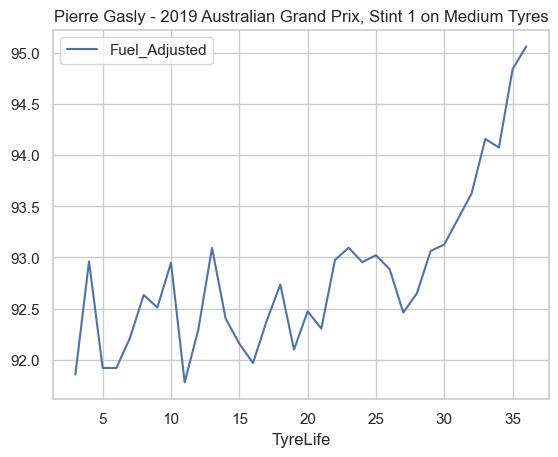

In [251]:
x = all_laps.loc[lambda d: (d["DriverNumber"]=="10")&(d["Season"]==2019)&(d["RoundNumber"]==1)&(d["Stint"]==1)]
x["adj"] = x["Fuel_Adjusted"] - x["LapTime"]
x.plot("TyreLife", "Fuel_Adjusted")
plt.title("Pierre Gasly - 2019 Australian Grand Prix, Stint 1 on Medium Tyres")

In [252]:
by_race = (
    all_laps
    .groupby(['Season', 'Track', 'Compound'])
    .agg(avg_lap_time=('Fuel_Adjusted', 'mean'),
         min_lap_time=('Fuel_Adjusted', 'min'),
         total_laps=('LapTime', 'count'),
        avg_laps=('TyreLife', 'mean'))
    .reset_index()
)

by_race

,Season,Track,Compound,avg_lap_time,min_lap_time,total_laps,avg_laps
0,2019,Austin,HARD,103.775272,98.746,412,13.774272
1,2019,Austin,MEDIUM,103.656525,97.257,261,10.720307
2,2019,Austin,SOFT,103.130028,96.469,177,10.124294
3,2019,Baku,MEDIUM,110.611915,106.469,599,17.293823
4,2019,Baku,SOFT,110.854161,103.459,168,8.005952
...,...,...,...,...,...,...,...
340,2025,Suzuka,MEDIUM,95.835034,92.039,414,12.862319
341,2025,Suzuka,SOFT,94.841661,91.556,56,9.232143
342,2025,Zandvoort,HARD,78.830975,73.429,433,19.972286
343,2025,Zandvoort,MEDIUM,77.997685,75.735,314,11.592357


## Tyre Degredation Model

In [811]:
from sklearn.linear_model import LinearRegression

deg_rates = []

for (season, track, session, driver, stint), stint_df in all_laps.groupby(['Season', 'Track', 'Session', 'Driver', 'Stint']):
    compound = stint_df['Compound'].iloc[0]

    if len(stint_df) < 5:
        continue
        
    if stint_df['TyreLife'].nunique() < 4:
        continue


    # Recover original Fuel_Adjusted range

    X = stint_df[['TyreLife']]
    y = stint_df['Fuel_Adjusted_norm']

    reg = LinearRegression()
    reg.fit(X, y)

    # Convert deg_rate back to original units
    deg_rate = reg.coef_[0]

    deg_rates.append({
        'Season': season,
        'Race': track,
        'Session': session,
        'Driver': driver,
        'Stint': stint,
        'Compound': compound,
        'deg_rate': deg_rate
    })

deg_rates = pd.DataFrame(deg_rates)

In [814]:
deg_rates = deg_rates[~deg_rates['Compound'].isin(['INTERMEDIATE', 'WET'])]

AVG:   0.1409561633261331
% Positive:  0.936882435974995
  Compound  deg_rate
2     SOFT  0.159298
0     HARD  0.141354
1   MEDIUM  0.131893


Text(0, 0.5, 'Degredation Rate')

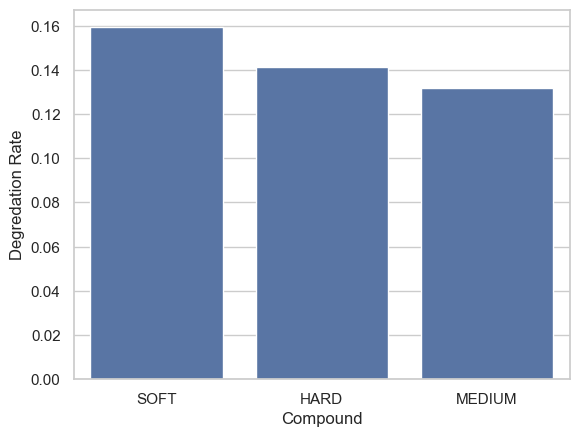

In [815]:
print('AVG:  ', deg_rates['deg_rate'].mean())
positive = (deg_rates['deg_rate'] > 0).sum()
total = len(deg_rates['deg_rate'])

print('% Positive: ', positive / total)


mean_deg = deg_rates.groupby('Compound')['deg_rate'].mean().reset_index()


# Sort by deg_rate
mean_deg_sorted = mean_deg.sort_values(by='deg_rate', ascending=False)
print(mean_deg_sorted)
# Barplot
sns.barplot(
    data=mean_deg_sorted,
    x='Compound',
    y='deg_rate'
)

plt.ylabel('Degredation Rate')

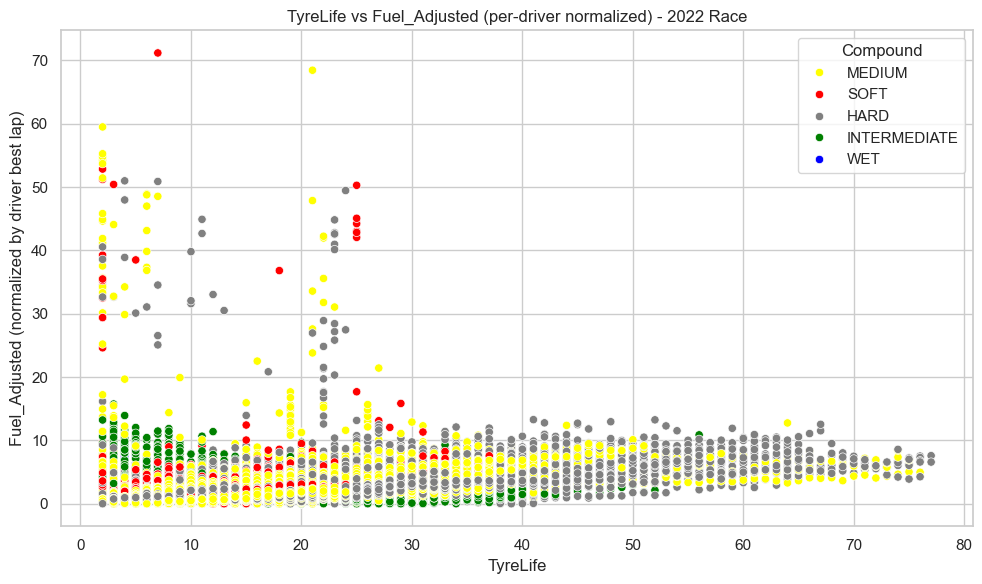

In [255]:
stint_key = ["Season", "Race", "Driver", "Compound", "Stint"]

# Filter race laps
all_laps = all_laps[(all_laps['Session'] == 'Race')].copy()

# Keep only dry tyres
dry_compounds = ['SOFT', 'MEDIUM', 'HARD']
dry_laps = all_laps[all_laps['Compound'].isin(dry_compounds)].copy()

sns.set(style="whitegrid")
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=all_laps,
    x='TyreLife',
    y='Fuel_Adjusted_norm',
    hue='Compound',
    palette=tyre_palette
)

plt.xlabel('TyreLife')
plt.ylabel('Fuel_Adjusted (normalized by driver best lap)')
plt.title('TyreLife vs Fuel_Adjusted (per-driver normalized) - 2022 Race')
plt.tight_layout()
plt.show()


In [256]:
deg_rates

,Season,Race,Session,Driver,Stint,Compound,deg_rate
0,2019,Austin,Race,ALB,2.0,MEDIUM,0.297981
1,2019,Austin,Race,ALB,3.0,MEDIUM,0.190364
2,2019,Austin,Race,ALB,4.0,SOFT,0.338636
3,2019,Austin,Race,BOT,1.0,MEDIUM,0.177043
4,2019,Austin,Race,BOT,2.0,HARD,0.242198
...,...,...,...,...,...,...,...
5317,2025,Zandvoort,Race,TSU,2.0,HARD,0.168888
5318,2025,Zandvoort,Race,TSU,3.0,SOFT,0.113616
5319,2025,Zandvoort,Race,VER,1.0,SOFT,0.182951
5320,2025,Zandvoort,Race,VER,2.0,MEDIUM,0.136902


In [257]:
deg_rate_per_track = (
    deg_rates.groupby(['Race', 'Compound'], as_index=False)['deg_rate']
      .mean()
      .rename(columns={'deg_rate': 'avg_deg_rate',
                      'Race': 'Track'})
)
deg_rate_per_track = deg_rate_per_track.set_index('Track')
deg_rate_per_track.to_parquet('Track_Deg_Rates.parquet')
deg_rate_per_track



,Compound,avg_deg_rate
Track,,
Algarve International Circuit,HARD,0.125861
Algarve International Circuit,MEDIUM,0.093211
Algarve International Circuit,SOFT,0.110662
Austin,HARD,0.153256
Austin,MEDIUM,0.159657
...,...,...
Yas Marina Circuit,MEDIUM,0.171557
Yas Marina Circuit,SOFT,0.160369
Zandvoort,HARD,0.149885


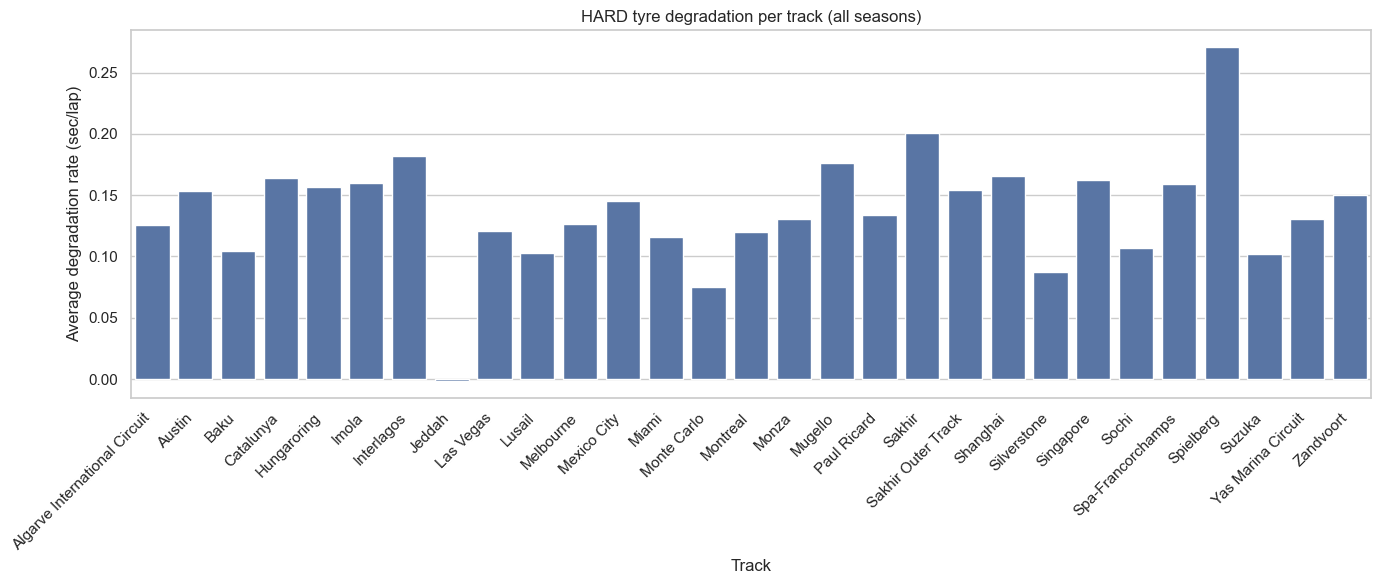

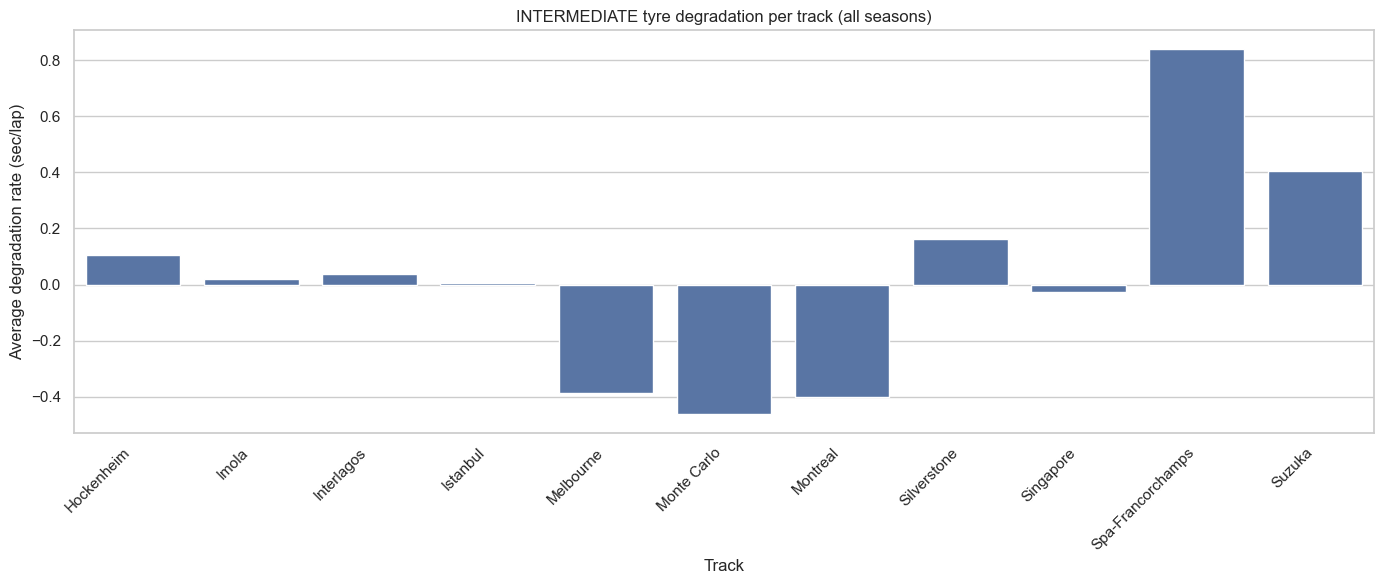

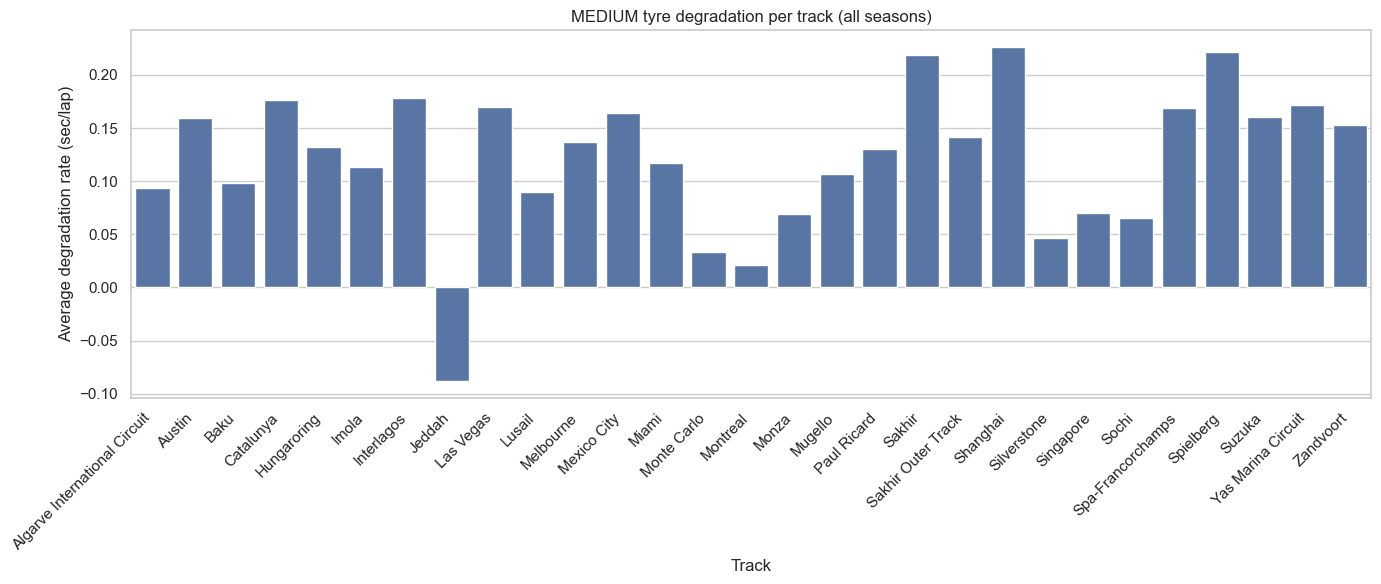

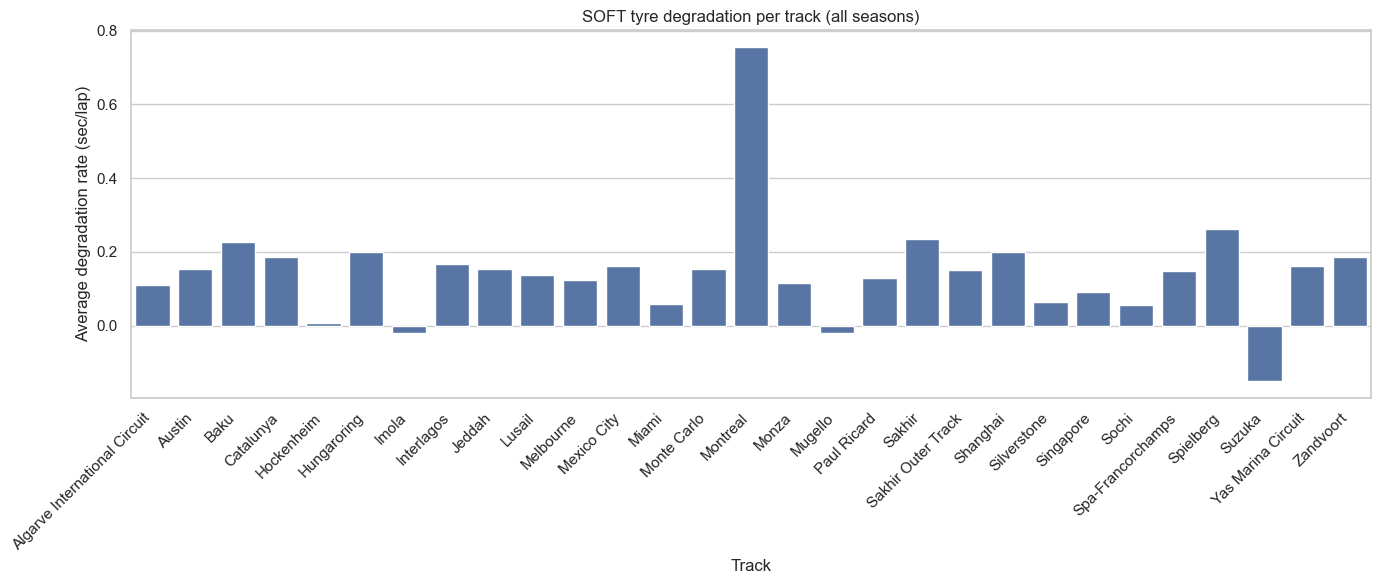

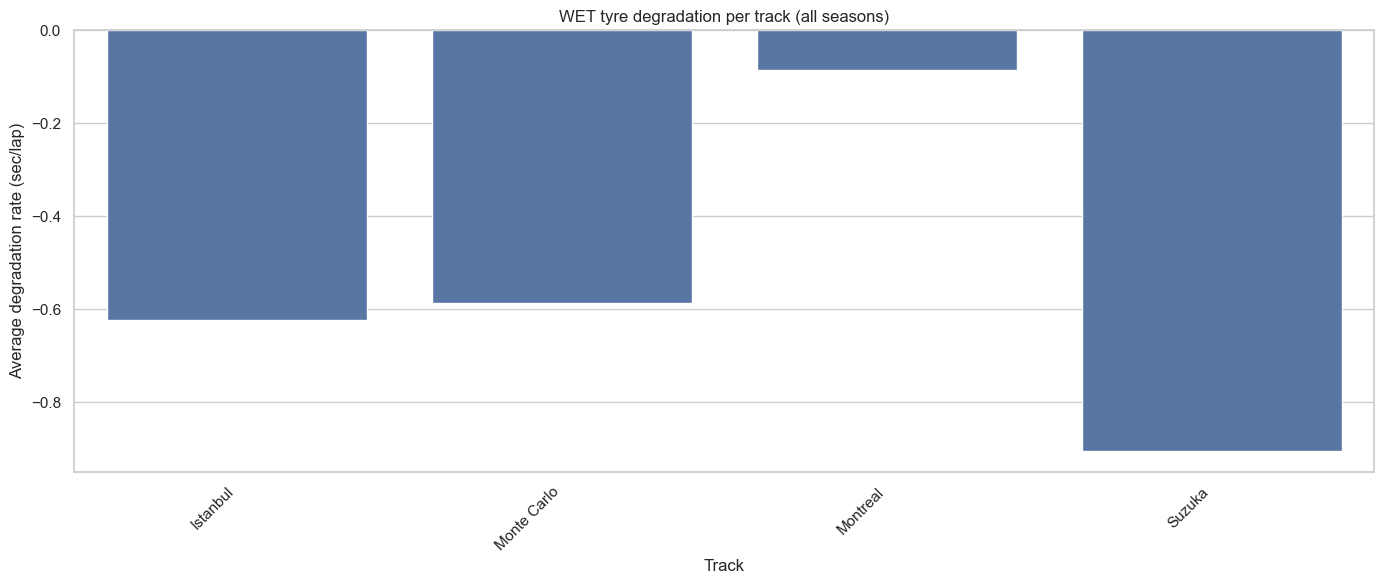

In [258]:
sns.set(style="whitegrid")

# Loop through each compound
for compound in sorted(deg_rate_per_track['Compound'].unique()):
    
    compound_df = deg_rate_per_track[deg_rate_per_track['Compound'] == compound]
    
    plt.figure(figsize=(14,6))
    
    sns.barplot(
        data=compound_df,
        x='Track',
        y='avg_deg_rate',
        #hue='Season',       # seasons side-by-side
        #palette='tab10'
    )
    
    plt.title(f'{compound} tyre degradation per track (all seasons)')
    plt.xticks(rotation=45, ha='right')
    plt.xlabel('Track')
    plt.ylabel('Average degradation rate (sec/lap)')
    #plt.legend(title='Season')
    
    plt.tight_layout()
    plt.show()

In [259]:
# Assuming your DataFrame is called deg_rate_per_track
deg_rate_per_track = deg_rate_per_track.reset_index()

In [260]:
deg_rate_per_track_pivot = deg_rate_per_track.pivot(
    index='Track', 
    columns='Compound', 
    values='avg_deg_rate'
).reset_index()

# Optional: flatten column names if needed
deg_rate_per_track_pivot.columns.name = None

# Replace NaNs with column means (excluding the 'Track' column)
for col in ['HARD', 'MEDIUM', 'SOFT', 'INTERMEDIATE', 'WET']:
    if col in deg_rate_per_track_pivot.columns:
        deg_rate_per_track_pivot[col].fillna(deg_rate_per_track_pivot[col].mean(), inplace=True)

deg_rate_per_track_pivot.rename(columns={
    'SOFT': 'soft',
    'MEDIUM': 'medium',
    'HARD': 'hard',
    'INTERMEDIATE': 'intermediate',
    'WET': 'wet'
}, inplace=True)

cols_order = ['soft', 'medium', 'hard', 'intermediate', 'wet']
deg_rate_per_track_pivot = deg_rate_per_track_pivot[['Track'] + [c for c in cols_order if c in deg_rate_per_track_pivot.columns]]

deg_rate_per_track_pivot = deg_rate_per_track_pivot.set_index('Track')
deg_rate_per_track_pivot

/tmp/ipykernel_3391382/3998870934.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  deg_rate_per_track_pivot[col].fillna(deg_rate_per_track_pivot[col].mean(), inplace=True)


,soft,medium,hard,intermediate,wet
Track,,,,,
Algarve International Circuit,0.110662,0.093211,0.125861,0.027288,-0.549880
Austin,0.153776,0.159657,0.153256,0.027288,-0.549880
Baku,0.226811,0.098341,0.104226,0.027288,-0.549880
Catalunya,0.185048,0.176334,0.163938,0.027288,-0.549880
Hockenheim,0.007433,0.122211,0.137255,0.104298,-0.549880
Hungaroring,0.199716,0.132622,0.157020,0.027288,-0.549880
Imola,-0.019521,0.113225,0.159877,0.020291,-0.549880
Interlagos,0.167409,0.178031,0.182012,0.037156,-0.549880
Istanbul,0.144779,0.122211,0.137255,0.004766,-0.623668


## Graphs

### Average Lap Time per Race by Tire Compound

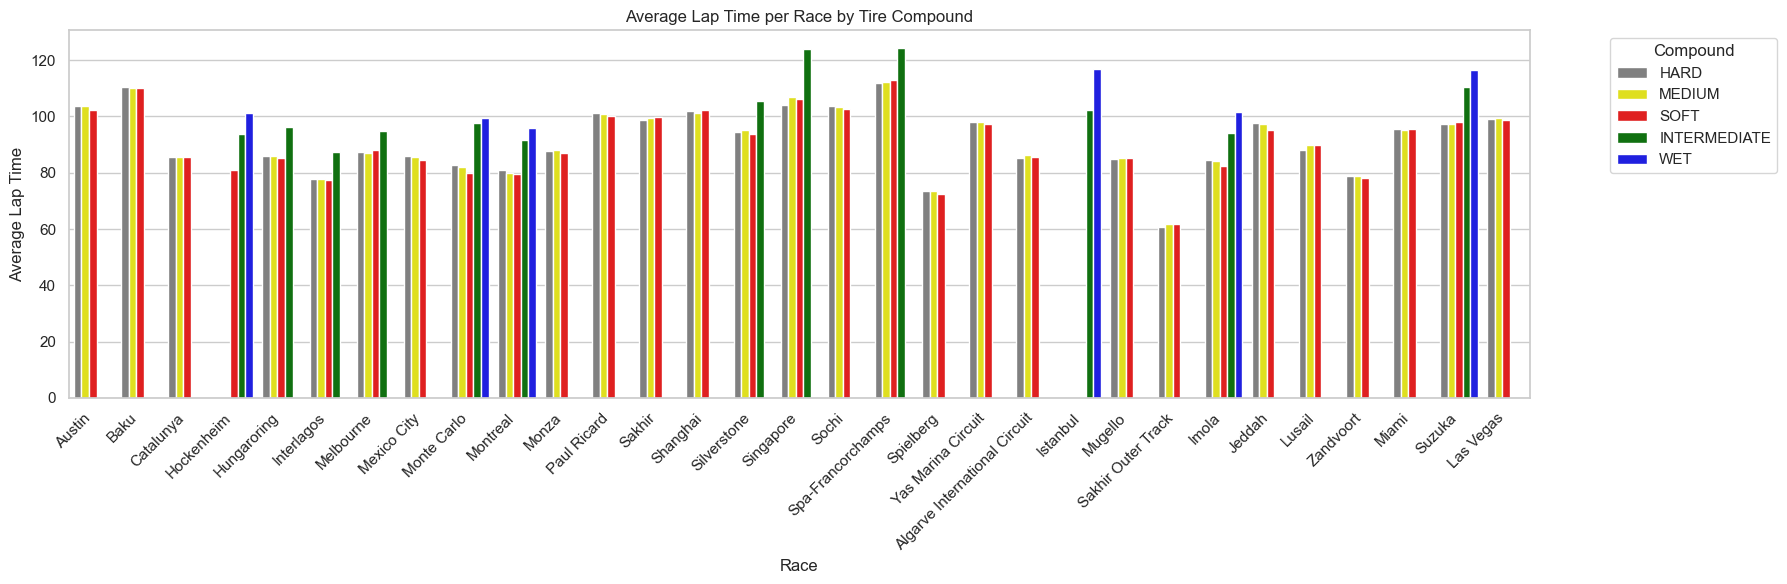

In [261]:
plt.figure(figsize=(18, 6))  # Make the figure wider

sns.barplot(
    data=by_race,
    x='Track',
    y='avg_lap_time',
    hue='Compound',
    palette=tyre_palette,
    errorbar=None
)

plt.xticks(rotation=45, ha='right')
plt.xlabel("Race")
plt.ylabel("Average Lap Time")
plt.title("Average Lap Time per Race by Tire Compound")
plt.legend(title="Compound", bbox_to_anchor=(1.05, 1), loc='upper left')  # Move legend outside
plt.tight_layout() 

plt.show()

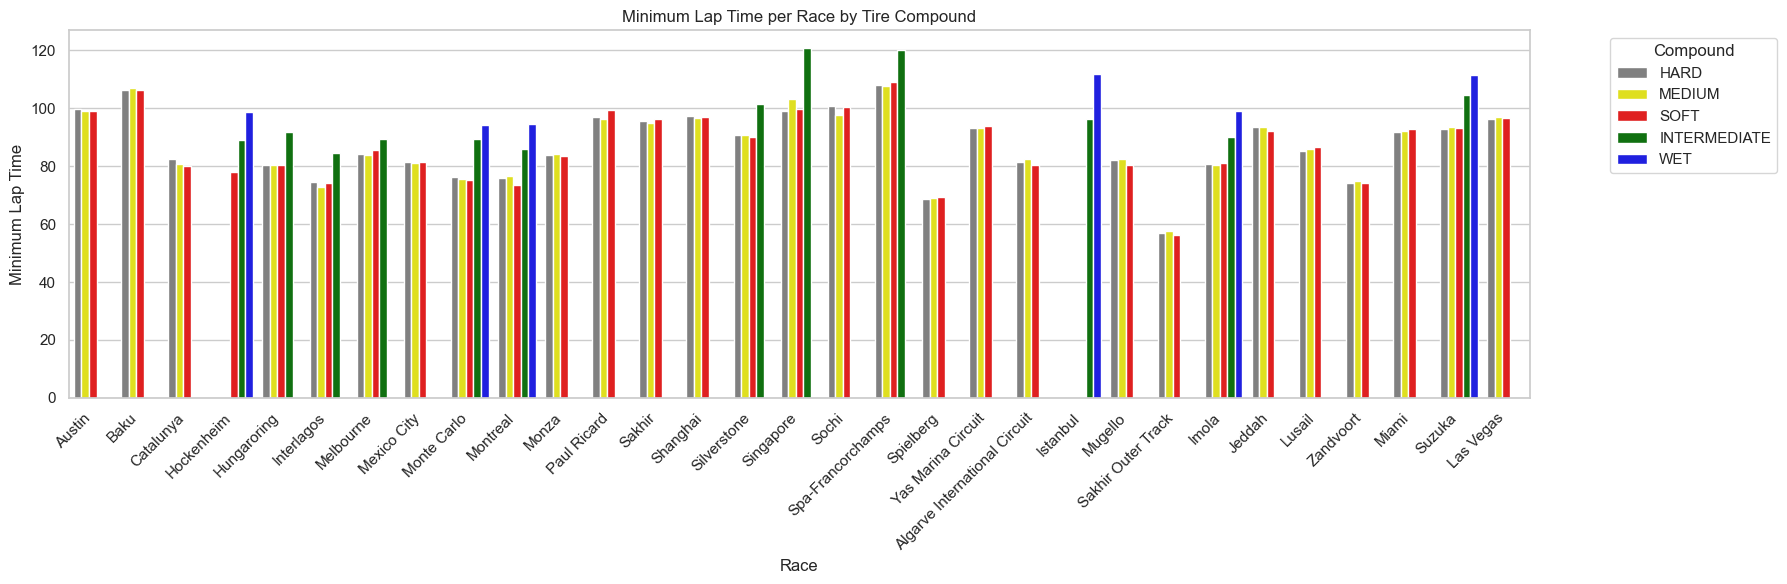

In [262]:
plt.figure(figsize=(18, 6))  # Make the figure wider

sns.barplot(
    data=by_race,
    x='Track',
    y='min_lap_time',
    hue='Compound',
    palette=tyre_palette,
    errorbar=None
)

plt.xticks(rotation=45, ha='right')
plt.xlabel("Race")
plt.ylabel("Minimum Lap Time")
plt.title("Minimum Lap Time per Race by Tire Compound")
plt.legend(title="Compound", bbox_to_anchor=(1.05, 1), loc='upper left')  # Move legend outside
plt.tight_layout() 

plt.show()

In [263]:
track_stats

,avg_pitstops,var_pitstops,avg_pitlane_time,pitstop_sample_size
Track,,,,
Algarve International Circuit,1.368421,0.356725,28.387781,19
Austin,1.689655,0.588613,25.558159,87
Baku,1.445946,0.524435,21.157259,74
Catalunya,2.349515,2.072720,23.871803,103
Hockenheim,2.500000,1.911765,22.542162,18
Hungaroring,2.471154,2.076830,23.038426,104
Imola,1.909091,0.914685,30.910146,66
Interlagos,2.275862,1.341620,25.308937,87
Istanbul,1.718750,0.660282,24.997201,32


# Team Stats

In [881]:
results = pd.read_parquet("qualifying_data_with_training_features.parquet")
results = results.drop(['Number of Laps', 'Circuit Length(km)', 'Race Distance(km)', 'Lap Record', 'Turns', 'DRS Zones', 'Cons_0', 'Cons_1', 'Cons_2',
       'Cons_3', 'Pace_0', 'Pace_1', 'Pace_2', 'Pace_3', 'Pace', 'Consistency', 'cluster', 'SpeedFL'], axis=1)
results

Abbreviation         TeamName TeamColor  \
Season DriverNumber RoundNumber                                           
2019   77           1                    BOT         Mercedes    00d2be   
       44           1                    HAM         Mercedes    00d2be   
       33           1                    VER  Red Bull Racing    1e41ff   
       5            1                    VET          Ferrari    dc0000   
       16           1                    LEC          Ferrari    dc0000   
...                                      ...              ...       ...   
2025   10           23                   GAS           Alpine    00A1E8   
       18           23                   STR     Aston Martin    229971   
       6            23                   HAD     Racing Bulls    6C98FF   
       87           23                   BEA     Haas F1 Team    9C9FA2   
       27           23                   HUL      Kick Sauber    01C00E   

                                       TeamId          FullName CountryCode  \
Season DriverNumber RoundNumber                                               
2019   77           1                mercedes   Valtteri Bottas               
       44           1                mercedes    Lewis Hamilton               
       33           1                red_bull    Max Verstappen               
       5            1                 ferrari  Sebastian Vettel               
       16           1                 ferrari   Charles Leclerc               
...                                       ...               ...         ...   
2025   10           23                 alpine      Pierre Gasly               
       18           23           aston_martin      Lance Stroll               
       6            23                     rb      Isack Hadjar               
       87           23                   haas    Oliver Bearman               
       27           23                 sauber   Nico Hulkenberg               

                                 Position ClassifiedPosition  GridPosition  \
Season DriverNumber RoundNumber                                              
2019   77           1                 1.0                  1           2.0   
       44           1                 2.0                  2           1.0   
       33           1                 3.0                  3           4.0   
       5            1                 4.0                  4           3.0   
       16           1                 5.0                  5           5.0   
...                                   ...                ...           ...   
2025   10           23               16.0                 16           9.0   
       18           23               17.0                 17          18.0   
       6            23               18.0                 18           6.0   
       87           23               19.0                  R          13.0   
       27           23               20.0                  R          11.0   

                                                  Time    Status  Points  \
Season DriverNumber RoundNumber                                            
2019   77           1           0 days 01:25:27.325000  Finished    26.0   
       44           1           0 days 00:00:20.886000  Finished    18.0   
       33           1           0 days 00:00:22.520000  Finished    15.0   
       5            1           0 days 00:00:57.109000  Finished    12.0   
       16           1           0 days 00:00:58.203000  Finished    10.0   
...                                                ...       ...     ...   
2025   10           23          0 days 00:00:04.941000    Lapped     0.0   
       18           23                             NaT   Retired     0.0   
       6            23                             NaT   Retired     0.0   
       87           23                             NaT   Retired     0.0   
       27           23                             NaT   Retired     0.0   

                        

In [882]:
import pandas as pd
import numpy as np

def add_team_quali_pace_index_weighted(results, lookback_races=8, half_life_races=3):
    """
    Adds exponentially weighted TeamQualiPaceIndexWeighted column to results.

    More recent races have higher weight.
    half_life_races=3 → race 3 races ago has 50% weight.

    No future leakage — only past races used.
    """

    df = results.copy()

    # Ensure correct format

    # Step 1: calculate raw index per race
    race_team_index = []

    for (season, round_num), race_df in df.groupby(['Season','RoundNumber']):

        pole = race_df['MinQualiTime'].min()

        race_df = race_df.copy()
        race_df['gap'] = race_df['MinQualiTime'] - pole

        team_gap = race_df.groupby('TeamName')['gap'].mean()

        max_gap = team_gap.max()

        if max_gap == 0:
            team_index = pd.Series(1.0, index=team_gap.index)
        else:
            team_index = 1 - (team_gap / max_gap)

        team_index = team_index.reset_index()
        team_index.columns = ['TeamName','TeamQualiPaceIndex_raw']
        team_index['Season'] = season
        team_index['RoundNumber'] = round_num

        race_team_index.append(team_index)

    team_index_df = pd.concat(race_team_index)

    # Step 2: sort correctly
    team_index_df = team_index_df.sort_values(
        ['TeamName','Season','RoundNumber']
    )

    # Step 3: exponential weighting
    weighted_list = []

    for team, team_df in team_index_df.groupby('TeamName'):

        team_df = team_df.copy()
        values = team_df['TeamQualiPaceIndex_raw'].values

        weighted_values = []

        for i in range(len(values)):

            start = max(0, i - lookback_races)
            window_vals = values[start:i]  # ONLY past races

            if len(window_vals) == 0:
                weighted_values.append(values[i])
                continue

            races_ago = np.arange(len(window_vals))[::-1]

            weights = 0.5 ** (races_ago / half_life_races)

            weighted_avg = np.sum(window_vals * weights) / np.sum(weights)

            weighted_values.append(weighted_avg)

        team_df['team_performance_index'] = weighted_values

        weighted_list.append(team_df)

    team_index_df = pd.concat(weighted_list)

    team_index_df = team_index_df.drop(columns=['TeamQualiPaceIndex_raw'])

    # Step 4: merge back
    df = df.merge(
        team_index_df,
        on=['Season','RoundNumber','TeamName'],
        how='left'
    )

    df['team_performance_index'] = df['team_performance_index'].fillna(0)

    return df

In [883]:
results = add_team_quali_pace_index_weighted(
    results,
    lookback_races=8,
    half_life_races=3
)

results

,Season,RoundNumber,Abbreviation,TeamName,TeamColor,TeamId,FullName,CountryCode,Position,ClassifiedPosition,GridPosition,Time,Status,Points,Laps,Country,EventName,Track,MinQualiTime,QualiPosition,TrackStatus,LapEndTime,Quali_AirTemp,Quali_Humidity,Quali_Pressure,Quali_Rainfall,Quali_TrackTemp,Quali_WindDirection,Quali_WindSpeed,FP3BestLapTime,FP3_AirTemp,FP3_TrackTemp,FP3_Humidity,FP3_Pressure,FP3_Rainfall,FP3_WindDirection,FP3_WindSpeed,FP2BestLapTime,FP2_AirTemp,FP2_TrackTemp,FP2_Humidity,FP2_Pressure,FP2_Rainfall,FP2_WindDirection,FP2_WindSpeed,FP2BestOverallLapTime,FP3BestOverallLapTime,MinOverallQualiTime,NormalizedLapTime,FP3Delta,FP2Delta,QualiDelta,TeamFP3Delta,TeamAvgQualiTime,PrevQualiDelta,Prev5QualiDeltas,TeamPrevQualiDelta,AvgDriverQualiTime,StdDriverQualiTime,AvgTeamQualiTime,AvgOverallQualiTime,StdNormLapTime,AvgNormLapTime,team_performance_index
0,2019,1,BOT,Mercedes,00d2be,mercedes,Valtteri Bottas,,1.0,1,2.0,0 days 01:25:27.325000,Finished,26.0,58.0,Australia,Australian Grand Prix,Melbourne,80.598,2.0,1,0 days 01:08:40.635000,23.1,69.8,1016.8,0,35.6,0.0,1.3,83.422,23.5,46.1,59.0,1017.9,0,342.0,0.5,82.648,22.0,41.7,55.9,1017.5,False,107.0,1.3,82.600,82.292,80.486,1.001392,1.130,0.048,0.112,0.5650,80.5420,1.130,1.1300,0.5650,79.433750,9.113470,79.402375,79.239250,0.003498,1.002594,0.988154
1,2019,1,HAM,Mercedes,00d2be,mercedes,Lewis Hamilton,,2.0,2,1.0,0 days 00:00:20.886000,Finished,18.0,58.0,Australia,Australian Grand Prix,Melbourne,80.486,1.0,1,0 days 01:16:22.363000,22.9,69.2,1016.8,0,34.3,161.0,2.9,82.292,23.3,45.8,59.5,1017.9,0,339.0,0.8,82.600,21.8,41.7,56.0,1017.6,False,149.0,1.8,82.600,82.292,80.486,1.000000,0.000,0.000,0.000,0.5650,80.5420,0.000,0.0000,0.5650,79.371000,9.159235,79.402375,79.239250,0.003331,1.001748,0.988154
2,2019,1,VER,Red Bull Racing,1e41ff,red_bull,Max Verstappen,,3.0,3,4.0,0 days 00:00:22.520000,Finished,15.0,58.0,Australia,Australian Grand Prix,Melbourne,81.320,4.0,1,0 days 01:17:38.851000,22.8,69.4,1016.8,0,34.3,158.0,1.4,83.481,23.4,45.2,59.7,1017.8,0,190.0,1.0,83.400,21.8,38.8,56.6,1017.7,False,170.0,1.6,82.600,82.292,80.486,1.010362,1.189,0.800,0.834,1.1320,82.1700,1.189,1.1890,1.1320,79.696250,9.363364,80.139000,79.239250,0.004275,1.005681,0.643786
3,2019,1,VET,Ferrari,dc0000,ferrari,Sebastian Vettel,,4.0,4,3.0,0 days 00:00:57.109000,Finished,12.0,58.0,Australia,Australian Grand Prix,Melbourne,81.190,3.0,1,0 days 01:16:57.375000,22.9,69.2,1016.8,0,34.3,161.0,2.9,82.556,23.3,45.6,58.6,1017.9,0,190.0,0.8,83.473,21.9,42.4,57.2,1017.5,False,167.0,1.0,82.600,82.292,80.486,1.008747,0.264,0.873,0.704,0.3605,81.3160,0.264,0.2640,0.3605,79.788750,9.071905,79.954375,79.239250,0.003464,1.007169,0.824432
4,2019,1,LEC,Ferrari,dc0000,ferrari,Charles Leclerc,,5.0,5,5.0,0 days 00:00:58.203000,Finished,10.0,58.0,Australia,Australian Grand Prix,Melbourne,81.442,5.0,1,0 days 01:09:03.401000,23.1,69.1,1016.7,0,35.5,172.0,0.7,82.749,23.3,45.8,59.5,1017.9,0,339.0,0.8,83.754,21.9,42.7,56.1,1017.5,False,190.0,2.5,82.600,82.292,80.486,1.011878,0.457,1.154,0.956,0.3605,81.3160,0.457,0.4570,0.3605,80.120000,8.740686,79.954375,79.239250,0.011665,1.011793,0.824432
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2389,2025,23,GAS,Alpine,00A1E8,alpine,Pierre Gasly,,16.0,16,9.0,0 days 00:00:04.941000,Lapped,0.0,56.0,Qatar,Qatar Grand Prix,Lusail,80.324,9.0,1,0 days 00:53:59.401000,20.4,74.0,1016.5,0,25.3,332.0,1.0,82.112,21.6,26.2,67.0,1017.7,0,177.0,0.9,82.424,25.5,31.1,49.0,1017.1,False,345.0,2.5,80.924,80.055,79.387,1.011803,2.057,1.500,0.937,2.1830,80.7305,3.606,1.5040,4.0000,83.314000,5.582255,83.692750,82.479333,0.004120,1.010303,0.155538
2390,2025,23,STR,Aston Martin,229971,aston_martin,Lance Stroll,,17.0,17,18.0,NaT,Retired,0.0,55.0,Qatar,Qatar Grand Prix,Lusail,81.058,19.0,1,0 days 00:31:02.

# Driver Stats

In [884]:
# Define features and target
X = results[['GridPosition', 'team_performance_index']].dropna()
y = results.loc[X.index, 'Position']  # target aligned with features

# Fit baseline model
baseline_model = LinearRegression()
baseline_model.fit(X, y)

# Step 2: Predict expected finish
expected_finish = baseline_model.predict(X)

# Optional: add predictions back to DataFrame
results.loc[X.index, 'expected_finish'] = expected_finish.round(3)
results['driver_skill'] = (results['Position'] - results['expected_finish'])

# Check
results[['GridPosition', 'team_performance_index', 'Position', 'expected_finish', 'driver_skill']]


,GridPosition,team_performance_index,Position,expected_finish,driver_skill
0,2.0,0.988154,1.0,3.857,-2.857
1,1.0,0.988154,2.0,3.429,-1.429
2,4.0,0.643786,3.0,6.935,-3.935
3,3.0,0.824432,4.0,5.341,-1.341
4,5.0,0.824432,5.0,6.196,-1.196
...,...,...,...,...,...
2389,9.0,0.155538,16.0,12.225,3.775
2390,18.0,0.374279,17.0,14.658,2.342
2391,6.0,0.569098,18.0,8.272,9.728
2392,13.0,0.314193,19.0,12.910,6.090


In [885]:
results.reset_index().groupby('Abbreviation')['driver_skill'].agg(['mean']).sort_values(by='mean', ascending=True)

,mean
Abbreviation,
BEA,-2.332696
VER,-1.744190
HAM,-1.363240
PIA,-1.109553
RUS,-0.917356
OCO,-0.802475
NOR,-0.605661
ALB,-0.393874
LEC,-0.351492


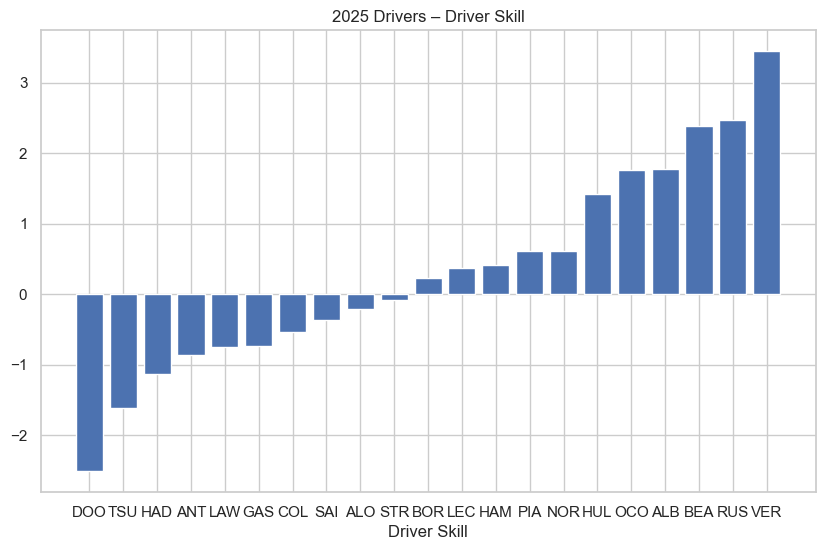

In [886]:
# Filter 2025 results
results_2025 = results.reset_index()
results_2025 = results_2025[results_2025['Season'] == 2025]

# Compute average driver skill for 2025 drivers
avgs_2025 = results_2025.groupby('Abbreviation')['driver_skill'].mean()

# Reverse the sign
avgs_2025_flipped = -avgs_2025

# Sort by flipped skill
avgs_2025_sorted = avgs_2025_flipped.sort_values(ascending=True)

# Horizontal bar chart
plt.figure(figsize=(10,6))
plt.bar(avgs_2025_sorted.index, avgs_2025_sorted.values)
plt.xlabel('Driver Skill')
plt.title('2025 Drivers – Driver Skill')
plt.show()

In [887]:
# Make sure Abbreviation is a column
df = results.reset_index()

# Sort by driver and round
df = df.sort_values(['Abbreviation', 'Season', 'RoundNumber'])

# 3-round rolling average
df['driver_skill_3r'] = (
    df.groupby('Abbreviation')['driver_skill']
      .transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean()).fillna(0)
)

df['driver_skill_10r'] = (
    df.groupby('Abbreviation')['driver_skill']
      .transform(lambda x: x.shift(1).rolling(10, min_periods=1).mean()).fillna(0)
)

df = df.sort_values(by=['Season', 'RoundNumber', 'Position'])
# Put back in your original index if you want
df = df.set_index(['Season', 'RoundNumber', 'Abbreviation'])
df
df[['driver_skill_3r', 'driver_skill_10r']]

driver_skill_3r  driver_skill_10r
Season RoundNumber Abbreviation                                   
2019   1           BOT                  0.000000            0.0000
                   HAM                  0.000000            0.0000
                   VER                  0.000000            0.0000
                   VET                  0.000000            0.0000
                   LEC                  0.000000            0.0000
...                                          ...               ...
2025   23          GAS                 -1.516667            0.5090
                   STR                  2.229000           -0.0212
                   HAD                 -0.371000            0.6712
                   BEA                 -5.272667           -2.9417
                   HUL                 -0.839667            0.1324

[2394 rows x 2 columns]

In [888]:
results = results.set_index(['Season', 'RoundNumber', 'Abbreviation']).merge(
    df[['driver_skill_3r', 'driver_skill_10r']],
    left_index=True,
    right_index=True,
    how='left'
)

In [889]:
# Compute cumulative points per driver per season
results = results.reset_index()
results['championship_points'] = results.groupby(['Season','Abbreviation'])['Points'].cumsum()

# Compute championship position per race
# Rank drivers by cumulative points at each RoundNumber within a Season
results['championship_position'] = results.groupby(['Season', 'RoundNumber'])['championship_points'] \
                                         .rank(method='min', ascending=False)

# Check first few rows
results[['Season','RoundNumber','Abbreviation','Points','championship_points','championship_position']].tail(10)

,Season,RoundNumber,Abbreviation,Points,championship_points,championship_position
2384,2025,23,ALB,0.0,70.0,8.0
2385,2025,23,HAM,0.0,131.0,7.0
2386,2025,23,BOR,0.0,19.0,19.0
2387,2025,23,COL,0.0,0.0,20.0
2388,2025,23,OCO,0.0,28.0,15.0
2389,2025,23,GAS,0.0,20.0,17.0
2390,2025,23,STR,0.0,22.0,16.0
2391,2025,23,HAD,0.0,35.0,14.0
2392,2025,23,BEA,0.0,39.0,12.0
2393,2025,23,HUL,0.0,49.0,10.0


In [890]:
results = results.reset_index()
results

,index,Season,RoundNumber,Abbreviation,TeamName,TeamColor,TeamId,FullName,CountryCode,Position,ClassifiedPosition,GridPosition,Time,Status,Points,Laps,Country,EventName,Track,MinQualiTime,QualiPosition,TrackStatus,LapEndTime,Quali_AirTemp,Quali_Humidity,Quali_Pressure,Quali_Rainfall,Quali_TrackTemp,Quali_WindDirection,Quali_WindSpeed,FP3BestLapTime,FP3_AirTemp,FP3_TrackTemp,FP3_Humidity,FP3_Pressure,FP3_Rainfall,FP3_WindDirection,FP3_WindSpeed,FP2BestLapTime,FP2_AirTemp,FP2_TrackTemp,FP2_Humidity,FP2_Pressure,FP2_Rainfall,FP2_WindDirection,FP2_WindSpeed,FP2BestOverallLapTime,FP3BestOverallLapTime,MinOverallQualiTime,NormalizedLapTime,FP3Delta,FP2Delta,QualiDelta,TeamFP3Delta,TeamAvgQualiTime,PrevQualiDelta,Prev5QualiDeltas,TeamPrevQualiDelta,AvgDriverQualiTime,StdDriverQualiTime,AvgTeamQualiTime,AvgOverallQualiTime,StdNormLapTime,AvgNormLapTime,team_performance_index,expected_finish,driver_skill,driver_skill_3r,driver_skill_10r,championship_points,championship_position
0,0,2019,1,BOT,Mercedes,00d2be,mercedes,Valtteri Bottas,,1.0,1,2.0,0 days 01:25:27.325000,Finished,26.0,58.0,Australia,Australian Grand Prix,Melbourne,80.598,2.0,1,0 days 01:08:40.635000,23.1,69.8,1016.8,0,35.6,0.0,1.3,83.422,23.5,46.1,59.0,1017.9,0,342.0,0.5,82.648,22.0,41.7,55.9,1017.5,False,107.0,1.3,82.600,82.292,80.486,1.001392,1.130,0.048,0.112,0.5650,80.5420,1.130,1.1300,0.5650,79.433750,9.113470,79.402375,79.239250,0.003498,1.002594,0.988154,3.857,-2.857,0.000000,0.0000,26.0,1.0
1,1,2019,1,HAM,Mercedes,00d2be,mercedes,Lewis Hamilton,,2.0,2,1.0,0 days 00:00:20.886000,Finished,18.0,58.0,Australia,Australian Grand Prix,Melbourne,80.486,1.0,1,0 days 01:16:22.363000,22.9,69.2,1016.8,0,34.3,161.0,2.9,82.292,23.3,45.8,59.5,1017.9,0,339.0,0.8,82.600,21.8,41.7,56.0,1017.6,False,149.0,1.8,82.600,82.292,80.486,1.000000,0.000,0.000,0.000,0.5650,80.5420,0.000,0.0000,0.5650,79.371000,9.159235,79.402375,79.239250,0.003331,1.001748,0.988154,3.429,-1.429,0.000000,0.0000,18.0,2.0
2,2,2019,1,VER,Red Bull Racing,1e41ff,red_bull,Max Verstappen,,3.0,3,4.0,0 days 00:00:22.520000,Finished,15.0,58.0,Australia,Australian Grand Prix,Melbourne,81.320,4.0,1,0 days 01:17:38.851000,22.8,69.4,1016.8,0,34.3,158.0,1.4,83.481,23.4,45.2,59.7,1017.8,0,190.0,1.0,83.400,21.8,38.8,56.6,1017.7,False,170.0,1.6,82.600,82.292,80.486,1.010362,1.189,0.800,0.834,1.1320,82.1700,1.189,1.1890,1.1320,79.696250,9.363364,80.139000,79.239250,0.004275,1.005681,0.643786,6.935,-3.935,0.000000,0.0000,15.0,3.0
3,3,2019,1,VET,Ferrari,dc0000,ferrari,Sebastian Vettel,,4.0,4,3.0,0 days 00:00:57.109000,Finished,12.0,58.0,Australia,Australian Grand Prix,Melbourne,81.190,3.0,1,0 days 01:16:57.375000,22.9,69.2,1016.8,0,34.3,161.0,2.9,82.556,23.3,45.6,58.6,1017.9,0,190.0,0.8,83.473,21.9,42.4,57.2,1017.5,False,167.0,1.0,82.600,82.292,80.486,1.008747,0.264,0.873,0.704,0.3605,81.3160,0.264,0.2640,0.3605,79.788750,9.071905,79.954375,79.239250,0.003464,1.007169,0.824432,5.341,-1.341,0.000000,0.0000,12.0,4.0
4,4,2019,1,LEC,Ferrari,dc0000,ferrari,Charles Leclerc,,5.0,5,5.0,0 days 00:00:58.203000,Finished,10.0,58.0,Australia,Australian Grand Prix,Melbourne,81.442,5.0,1,0 days 01:09:03.401000,23.1,69.1,1016.7,0,35.5,172.0,0.7,82.749,23.3,45.8,59.5,1017.9,0,339.0,0.8,83.754,21.9,42.7,56.1,1017.5,False,190.0,2.5,82.600,82.292,80.486,1.011878,0.457,1.154,0.956,0.3605,81.3160,0.457,0.4570,0.3605,80.120000,8.740686,79.954375,79.239250,0.011665,1.011793,0.824432,6.196,-1.196,0.000000,0.0000,10.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2389,2389,2025,23,GAS,Alpine,00A1E8,alpine,Pierre Gasly,,16.0,16,9.0,0 days 00:00:04.941000,Lapped,0.0,56.0,Qatar,Qatar Grand Prix,Lusail,80.324,9.0,1,0 days 00:53:59.401000,20.4,74.0,1016.5,0,25.3,332.0,1.0,82.112,21.6,26.2,67.0,1017.7,0,177.0,0.9,82.424,25

In [891]:
# Reset the index fully so all index levels become columns
results_reset = results.reset_index(drop=True)

In [892]:
# Now 'Season' should exist as a column
results_no2024 = results_reset[results_reset['Season'] != 2025].copy()

# Calculate quali_to_race
results_no2024['quali_to_race'] = results_no2024['QualiPosition'] - results_no2024['Position']

# Compute mean per track
mean_quali_to_race = results_no2024.groupby('Abbreviation')['quali_to_race'].mean()

# Map it back to the original dataframe (if you want)
results_reset['mean_quali_to_race'] = results_reset['Abbreviation'].map(mean_quali_to_race).fillna(0)
results_reset = results_reset.set_index(['Season', 'RoundNumber', 'Abbreviation'])
# Optional: assign back to your original results
results = results_reset

In [893]:
results

index         TeamName TeamColor  \
Season RoundNumber Abbreviation                                     
2019   1           BOT               0         Mercedes    00d2be   
                   HAM               1         Mercedes    00d2be   
                   VER               2  Red Bull Racing    1e41ff   
                   VET               3          Ferrari    dc0000   
                   LEC               4          Ferrari    dc0000   
...                                ...              ...       ...   
2025   23          GAS            2389           Alpine    00A1E8   
                   STR            2390     Aston Martin    229971   
                   HAD            2391     Racing Bulls    6C98FF   
                   BEA            2392     Haas F1 Team    9C9FA2   
                   HUL            2393      Kick Sauber    01C00E   

                                       TeamId          FullName CountryCode  \
Season RoundNumber Abbreviation                                               
2019   1           BOT               mercedes   Valtteri Bottas               
                   HAM               mercedes    Lewis Hamilton               
                   VER               red_bull    Max Verstappen               
                   VET                ferrari  Sebastian Vettel               
                   LEC                ferrari   Charles Leclerc               
...                                       ...               ...         ...   
2025   23          GAS                 alpine      Pierre Gasly               
                   STR           aston_martin      Lance Stroll               
                   HAD                     rb      Isack Hadjar               
                   BEA                   haas    Oliver Bearman               
                   HUL                 sauber   Nico Hulkenberg               

                                 Position ClassifiedPosition  GridPosition  \
Season RoundNumber Abbreviation                                              
2019   1           BOT                1.0                  1           2.0   
                   HAM                2.0                  2           1.0   
                   VER                3.0                  3           4.0   
                   VET                4.0                  4           3.0   
                   LEC                5.0                  5           5.0   
...                                   ...                ...           ...   
2025   23          GAS               16.0                 16           9.0   
                   STR               17.0                 17          18.0   
                   HAD               18.0                 18           6.0   
                   BEA               19.0                  R          13.0   
                   HUL               20.0                  R          11.0   

                                                  Time    Status  Points  \
Season RoundNumber Abbreviation                                            
2019   1           BOT          0 days 01:25:27.325000  Finished    26.0   
                   HAM          0 days 00:00:20.886000  Finished    18.0   
                   VER          0 days 00:00:22.520000  Finished    15.0   
                   VET          0 days 00:00:57.109000  Finished    12.0   
                   LEC          0 days 00:00:58.203000  Finished    10.0   
...                                                ...       ...     ...   
2025   23          GAS          0 days 00:00:04.941000    Lapped     0.0   
                   STR                             NaT   Retired     0.0   
                   HAD                             NaT   Retired     0.0   
                   BEA                             NaT   Retired     0.0   
                   HUL                             NaT   Retired     0.0   

                                 Laps    Country              EventName  \
Season RoundNumber Abbreviat

# Joining

In [639]:
track_info = track_info.join(track_stats, how='left', rsuffix='_stats')
track_info = track_info.join(stoppage_stats, how='left', rsuffix='_stats')
track_info = track_info.join(deg_rate_per_track_pivot, how='left', rsuffix='_stats')
track_info = track_info.join(overtake_features, how='left', rsuffix='_stats')
track_info = track_info.join(track_corr, how='left', rsuffix='_stats')

In [640]:
track_info.to_parquet('track_info.parquet')
track_info

,laps,lap_record,drs_zones,length,race_distance,turns,avg_pitstops,var_pitstops,avg_pitlane_time,pitstop_sample_size,sc_probability,avg_sc_count,std_sc_count,red_flag_probability,incident_probability,soft,medium,hard,intermediate,wet,avg_overtakes_z,std_overtakes,overtake_samples,grid_finish_correlation,avg_pitstops_stats,var_pitstops_stats,avg_pitlane_time_stats,pitstop_sample_size_stats,sc_probability_stats,avg_sc_count_stats,std_sc_count_stats,red_flag_probability_stats,incident_probability_stats,soft_stats,medium_stats,hard_stats,intermediate_stats,wet_stats,avg_overtakes_z_stats,std_overtakes_stats,overtake_samples_stats,grid_finish_correlation_stats
Track,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Melbourne,58,84.125,3,5.303,307.574,16,2.250000,2.156780,19.751415,60,0.50,1.25,1.50,0.0,0.50,0.122710,0.137218,0.126500,-0.387394,-0.549880,-0.586855,30.681156,4,0.548004,2.250000,2.156780,19.751415,60,0.50,1.25,1.50,0.0,0.50,0.122710,0.137218,0.126500,-0.387394,-0.549880,-0.586855,30.681156,4,0.548004
Sakhir,57,91.447,3,5.412,308.238,15,2.388889,1.323988,25.574388,108,0.83,1.00,0.63,0.0,0.83,0.234178,0.218321,0.200361,0.027288,-0.549880,-0.250190,18.519359,6,0.675424,2.388889,1.323988,25.574388,108,0.83,1.00,0.63,0.0,0.83,0.234178,0.218321,0.200361,0.027288,-0.549880,-0.250190,18.519359,6,0.675424
Shanghai,56,92.238,2,5.451,305.066,16,1.382979,0.371878,25.239660,47,0.33,0.67,1.15,0.0,0.33,0.199333,0.226171,0.165865,0.027288,-0.549880,2.114913,305.964595,3,0.639970,1.382979,0.371878,25.239660,47,0.33,0.67,1.15,0.0,0.33,0.199333,0.226171,0.165865,0.027288,-0.549880,2.114913,305.964595,3,0.639970
Baku,51,103.009,2,6.003,306.049,20,1.445946,0.524435,21.157259,74,0.40,0.40,0.55,0.0,0.40,0.226811,0.098341,0.104226,0.027288,-0.549880,-0.544596,10.488088,5,0.467080,1.445946,0.524435,21.157259,74,0.40,0.40,0.55,0.0,0.40,0.226811,0.098341,0.104226,0.027288,-0.549880,-0.544596,10.488088,5,0.467080
Catalunya,66,78.441,2,4.655,307.104,16,2.349515,2.072720,23.871803,103,0.50,0.50,0.55,0.0,0.50,0.185048,0.176334,0.163938,0.027288,-0.549880,-0.372742,25.406036,6,0.763599,2.349515,2.072720,23.871803,103,0.50,0.50,0.55,0.0,0.50,0.185048,0.176334,0.163938,0.027288,-0.549880,-0.372742,25.406036,6,0.763599
Monte Carlo,78,74.260,1,3.337,260.286,19,1.685714,0.740373,25.760561,70,0.40,0.40,0.55,0.0,0.40,0.153984,0.033086,0.075081,-0.461705,-0.587626,-0.864075,16.422545,5,0.763308,1.685714,0.740373,25.760561,70,0.40,0.40,0.55,0.0,0.40,0.153984,0.033086,0.075081,-0.461705,-0.587626,-0.864075,16.422545,5,0.763308
Montreal,70,73.078,3,4.361,305.270,14,2.315789,2.077068,23.718365,57,0.75,1.00,0.82,0.0,0.75,0.754989,0.021036,0.119687,-0.400575,-0.084127,-0.557273,28.053520,4,0.593442,2.315789,2.077068,23.718365,57,0.75,1.00,0.82,0.0,0.75,0.754989,0.021036,0.119687,-0.400575,-0.084127,-0.557273,28.053520,4,0.593442
Paul Ricard,53,92.740,2,5.842,309.690,15,1.100000,0.094737,37.832250,20,0.33,0.33,0.58,0.0,0.33,0.129377,0.130073,0.133673,0.027288,-0.549880,-0.572768,29.022979,3,0.656956,1.100000,0.094737,37.832250,20,0.33,0.33,0.58,0.0,0.33,0.129377,0.130073,0.133673,0.027288,-0.549880,-0.572768,29.022979,3,0.656956
Spielberg,71,66.957,3,4.318,306.452,10,2.256881,1.229698,24.748481,109,0.43,0.86,1.46,0.0,0.43,0.260703,0.221135,0.270747,0.027288,-0.549880,0.924815,289.182427,7,0.596882,2.256881,1.229698,24.748481,109,0.43,0.86,1.46,0.0,0.43,0.260703,0.221135,0.270747,0.027288,-0.549880,0.924815,289.182427,7,0.596882


# Building the DataFrame

In [832]:
results = results.set_index(['Season', 'RoundNumber', 'Abbreviation'])

KeyError: "None of ['Season', 'RoundNumber', 'Abbreviation'] are in the columns"

### Rolling Statistics
Replaced missing data with the Qualifying Position

In [894]:

r2 = results.copy()
r2 = r2.reset_index()
#r2 = r2.drop(columns='index')
r2['RoundNumber'] = r2['RoundNumber'] + 1
r2['Prev5RacePositions'] = (
    r2.groupby(['Abbreviation', 'Season'])['Position']
      .transform(lambda x: x.shift().rolling(5, min_periods=1).mean())
).fillna(r2['QualiPosition'])

r2['avg_finish_season'] = (
    r2.groupby(['Abbreviation', 'Season'])['Position']
      .transform(lambda x: x.shift().expanding().mean())
).fillna(r2['QualiPosition'])

r2 = r2.set_index(['Season', 'RoundNumber', 'Abbreviation'])
results = results.join(r2[['avg_finish_season', 'Prev5RacePositions']])
results['Prev5RacePositions'] = results['Prev5RacePositions'].fillna(results['QualiPosition'])
results['avg_finish_season'] = results['avg_finish_season'].fillna(results['QualiPosition'])

In [895]:
results

index         TeamName TeamColor  \
Season RoundNumber Abbreviation                                     
2019   1           BOT               0         Mercedes    00d2be   
                   HAM               1         Mercedes    00d2be   
                   VER               2  Red Bull Racing    1e41ff   
                   VET               3          Ferrari    dc0000   
                   LEC               4          Ferrari    dc0000   
...                                ...              ...       ...   
2025   23          GAS            2389           Alpine    00A1E8   
                   STR            2390     Aston Martin    229971   
                   HAD            2391     Racing Bulls    6C98FF   
                   BEA            2392     Haas F1 Team    9C9FA2   
                   HUL            2393      Kick Sauber    01C00E   

                                       TeamId          FullName CountryCode  \
Season RoundNumber Abbreviation                                               
2019   1           BOT               mercedes   Valtteri Bottas               
                   HAM               mercedes    Lewis Hamilton               
                   VER               red_bull    Max Verstappen               
                   VET                ferrari  Sebastian Vettel               
                   LEC                ferrari   Charles Leclerc               
...                                       ...               ...         ...   
2025   23          GAS                 alpine      Pierre Gasly               
                   STR           aston_martin      Lance Stroll               
                   HAD                     rb      Isack Hadjar               
                   BEA                   haas    Oliver Bearman               
                   HUL                 sauber   Nico Hulkenberg               

                                 Position ClassifiedPosition  GridPosition  \
Season RoundNumber Abbreviation                                              
2019   1           BOT                1.0                  1           2.0   
                   HAM                2.0                  2           1.0   
                   VER                3.0                  3           4.0   
                   VET                4.0                  4           3.0   
                   LEC                5.0                  5           5.0   
...                                   ...                ...           ...   
2025   23          GAS               16.0                 16           9.0   
                   STR               17.0                 17          18.0   
                   HAD               18.0                 18           6.0   
                   BEA               19.0                  R          13.0   
                   HUL               20.0                  R          11.0   

                                                  Time    Status  Points  \
Season RoundNumber Abbreviation                                            
2019   1           BOT          0 days 01:25:27.325000  Finished    26.0   
                   HAM          0 days 00:00:20.886000  Finished    18.0   
                   VER          0 days 00:00:22.520000  Finished    15.0   
                   VET          0 days 00:00:57.109000  Finished    12.0   
                   LEC          0 days 00:00:58.203000  Finished    10.0   
...                                                ...       ...     ...   
2025   23          GAS          0 days 00:00:04.941000    Lapped     0.0   
                   STR                             NaT   Retired     0.0   
                   HAD                             NaT   Retired     0.0   
                   BEA                             NaT   Retired     0.0   
                   HUL                             NaT   Retired     0.0   

                                 Laps    Country              EventName  \
Season RoundNumber Abbreviat

In [896]:
results = results.reset_index().merge(track_info,on='Track')

In [897]:
results

,Season,RoundNumber,Abbreviation,index,TeamName,TeamColor,TeamId,FullName,CountryCode,Position,ClassifiedPosition,GridPosition,Time,Status,Points,Laps,Country,EventName,Track,MinQualiTime,QualiPosition,TrackStatus,LapEndTime,Quali_AirTemp,Quali_Humidity,Quali_Pressure,Quali_Rainfall,Quali_TrackTemp,Quali_WindDirection,Quali_WindSpeed,FP3BestLapTime,FP3_AirTemp,FP3_TrackTemp,FP3_Humidity,FP3_Pressure,FP3_Rainfall,FP3_WindDirection,FP3_WindSpeed,FP2BestLapTime,FP2_AirTemp,FP2_TrackTemp,FP2_Humidity,FP2_Pressure,FP2_Rainfall,FP2_WindDirection,FP2_WindSpeed,FP2BestOverallLapTime,FP3BestOverallLapTime,MinOverallQualiTime,NormalizedLapTime,FP3Delta,FP2Delta,QualiDelta,TeamFP3Delta,TeamAvgQualiTime,PrevQualiDelta,Prev5QualiDeltas,TeamPrevQualiDelta,AvgDriverQualiTime,StdDriverQualiTime,AvgTeamQualiTime,AvgOverallQualiTime,StdNormLapTime,AvgNormLapTime,team_performance_index,expected_finish,driver_skill,driver_skill_3r,driver_skill_10r,championship_points,championship_position,mean_quali_to_race,avg_finish_season,Prev5RacePositions,laps,lap_record,drs_zones,length,race_distance,turns,avg_pitstops,var_pitstops,avg_pitlane_time,pitstop_sample_size,sc_probability,avg_sc_count,std_sc_count,red_flag_probability,incident_probability,soft,medium,hard,intermediate,wet,avg_overtakes_z,std_overtakes,overtake_samples,grid_finish_correlation,avg_pitstops_stats,var_pitstops_stats,avg_pitlane_time_stats,pitstop_sample_size_stats,sc_probability_stats,avg_sc_count_stats,std_sc_count_stats,red_flag_probability_stats,incident_probability_stats,soft_stats,medium_stats,hard_stats,intermediate_stats,wet_stats,avg_overtakes_z_stats,std_overtakes_stats,overtake_samples_stats,grid_finish_correlation_stats
0,2019,1,BOT,0,Mercedes,00d2be,mercedes,Valtteri Bottas,,1.0,1,2.0,0 days 01:25:27.325000,Finished,26.0,58.0,Australia,Australian Grand Prix,Melbourne,80.598,2.0,1,0 days 01:08:40.635000,23.1,69.8,1016.8,0,35.6,0.0,1.3,83.422,23.5,46.1,59.0,1017.9,0,342.0,0.5,82.648,22.0,41.7,55.9,1017.5,False,107.0,1.3,82.600,82.292,80.486,1.001392,1.130,0.048,0.112,0.5650,80.5420,1.130,1.1300,0.5650,79.433750,9.113470,79.402375,79.239250,0.003498,1.002594,0.988154,3.857,-2.857,0.000000,0.0000,26.0,1.0,-1.686869,2.000000,2.0,58,84.125,3,5.303,307.574,16,2.250000,2.156780,19.751415,60,0.50,1.25,1.50,0.0,0.50,0.122710,0.137218,0.126500,-0.387394,-0.54988,-0.586855,30.681156,4,0.548004,2.250000,2.156780,19.751415,60,0.50,1.25,1.50,0.0,0.50,0.122710,0.137218,0.126500,-0.387394,-0.54988,-0.586855,30.681156,4,0.548004
1,2019,1,HAM,1,Mercedes,00d2be,mercedes,Lewis Hamilton,,2.0,2,1.0,0 days 00:00:20.886000,Finished,18.0,58.0,Australia,Australian Grand Prix,Melbourne,80.486,1.0,1,0 days 01:16:22.363000,22.9,69.2,1016.8,0,34.3,161.0,2.9,82.292,23.3,45.8,59.5,1017.9,0,339.0,0.8,82.600,21.8,41.7,56.0,1017.6,False,149.0,1.8,82.600,82.292,80.486,1.000000,0.000,0.000,0.000,0.5650,80.5420,0.000,0.0000,0.5650,79.371000,9.159235,79.402375,79.239250,0.003331,1.001748,0.988154,3.429,-1.429,0.000000,0.0000,18.0,2.0,0.010204,1.000000,1.0,58,84.125,3,5.303,307.574,16,2.250000,2.156780,19.751415,60,0.50,1.25,1.50,0.0,0.50,0.122710,0.137218,0.126500,-0.387394,-0.54988,-0.586855,30.681156,4,0.548004,2.250000,2.156780,19.751415,60,0.50,1.25,1.50,0.0,0.50,0.122710,0.137218,0.126500,-0.387394,-0.54988,-0.586855,30.681156,4,0.548004
2,2019,1,VER,2,Red Bull Racing,1e41ff,red_bull,Max Verstappen,,3.0,3,4.0,0 days 00:00:22.520000,Finished,15.0,58.0,Australia,Australian Grand Prix,Melbourne,81.320,4.0,1,0 days 01:17:38.851000,22.8,69.4,1016.8,0,34.3,158.0,1.4,83.481,23.4,45.2,59.7,1017.8,0,190.0,1.0,83.400,21.8,38.8,56.6,1017.7,False,170.0,1.6,82.600,82.292,80.486,1.010362,1.189,0.800,0.834,1.1320,82.1700,1.189,1.1890,1.1320,79.696250,9.363364,80.139000,79.239250,0.004275,1.005681,0.643786,6.935,-3.935,0.000000,0.0000,15.0,3.0,-1.510204,4.000000,4.0,58,84.125,3,5.303,307.574,16,2.250000,2.156780,19.751415,60,0.50,1.25,1.50,0.0,0.50,0.122710,0.137218,0.126500,-0.387394,-0.54988,-0.586855,30.681156,4,0.5480

In [898]:
# Ensure results is sorted properly
df = results.reset_index().sort_values(['Abbreviation', 'Season', 'RoundNumber'])

# Create DNF column
df['DNF'] = (df['ClassifiedPosition'] == 'R').astype(int)

# Rolling DNF % over last 20 races (excluding current race)
df['DNF_pct'] = (
    df.groupby('Abbreviation')['DNF']
      .shift(1)                       # don't include current race
      .rolling(20, min_periods=1)     # use available races if < 20
      .mean()
)

# Merge back to original results
results = results.reset_index().merge(
    df[['Season','RoundNumber','Abbreviation','DNF_pct']],
    on=['Season','RoundNumber','Abbreviation'],
    how='left'
)

In [899]:
results = (
    results
    .merge(
        first_lap_avg_pos_change[['avg_first_lap_change', 'Track', 'GridPosition']],
        on=['Track', 'GridPosition'],
        how='left'
    )
    .set_index(['Season', 'RoundNumber', 'Abbreviation'])
)

In [900]:
results['expected_position_change'] = results['GridPosition'] * (1- results['grid_finish_correlation'])

In [901]:
df = results.reset_index().sort_values(['Abbreviation', 'Season', 'RoundNumber'])
teammates = df[['Season','RoundNumber','TeamName','Abbreviation','Prev5RacePositions', 'QualiPosition']].copy()

teammates = teammates.rename(columns={
    'Abbreviation': 'teammate',
    'QualiPosition': 'teammate_quali_position',
    'Prev5RacePositions': 'teammate_avg_finish_last_5'
})

df = df.merge(
    teammates,
    on=['Season','RoundNumber','TeamName'],
    how='left'
)

# remove self-matches
df = df[df['Abbreviation'] != df['teammate']]

df = df.drop(columns=['teammate'])

results = results.reset_index().merge(
    df[['Season','RoundNumber','Abbreviation','teammate_avg_finish_last_5', 'teammate_quali_position']],
    on=['Season','RoundNumber','Abbreviation'],
    how='left'
).set_index(['Season','RoundNumber','Abbreviation'])

In [904]:
features = results[['QualiPosition', 'avg_pitstops', 'var_pitstops', 'avg_pitlane_time', 'soft', 'medium', 'hard', 'avg_overtakes_z', 'drs_zones',
                    'avg_first_lap_change', 'sc_probability', 'avg_sc_count', 'avg_first_lap_change', 'expected_position_change', 'grid_finish_correlation',
                    'team_performance_index', 'expected_finish', 'driver_skill_3r', 'driver_skill_10r', 'mean_quali_to_race', 'avg_finish_season',
                    'Prev5RacePositions', 'teammate_avg_finish_last_5','teammate_quali_position', 'DNF_pct', 'championship_points', 'championship_position', 'Position'
    ]]

features = features.dropna(axis=0)
features

QualiPosition  avg_pitstops  var_pitstops  \
Season RoundNumber Abbreviation                                              
2019   1           BOT                     2.0      2.250000      2.156780   
                   HAM                     1.0      2.250000      2.156780   
                   VER                     4.0      2.250000      2.156780   
                   VET                     3.0      2.250000      2.156780   
                   LEC                     5.0      2.250000      2.156780   
...                                        ...           ...           ...   
2025   23          GAS                     9.0      2.396552      1.366304   
                   STR                    19.0      2.396552      1.366304   
                   HAD                     6.0      2.396552      1.366304   
                   BEA                    13.0      2.396552      1.366304   
                   HUL                    11.0      2.396552      1.366304   

                                 avg_pitlane_time      soft    medium  \
Season RoundNumber Abbreviation                                         
2019   1           BOT                  19.751415  0.122710  0.137218   
                   HAM                  19.751415  0.122710  0.137218   
                   VER                  19.751415  0.122710  0.137218   
                   VET                  19.751415  0.122710  0.137218   
                   LEC                  19.751415  0.122710  0.137218   
...                                           ...       ...       ...   
2025   23          GAS                  29.103284  0.137963  0.089371   
                   STR                  29.103284  0.137963  0.089371   
                   HAD                  29.103284  0.137963  0.089371   
                   BEA                  29.103284  0.137963  0.089371   
                   HUL                  29.103284  0.137963  0.089371   

                                     hard  avg_overtakes_z  drs_zones  \
Season RoundNumber Abbreviation                                         
2019   1           BOT           0.126500        -0.586855          3   
                   HAM           0.126500        -0.586855          3   
                   VER           0.126500        -0.586855          3   
                   VET           0.126500        -0.586855          3   
                   LEC           0.126500        -0.586855          3   
...                                   ...              ...        ...   
2025   23          GAS           0.102774         1.644428          1   
                   STR           0.102774         1.644428          1   
                   HAD           0.102774         1.644428          1   
                   BEA           0.102774         1.644428          1   
                   HUL           0.102774         1.644428          1   

                                 avg_first_lap_change  sc_probability  \
Season RoundNumber Abbreviation                                         
2019   1           BOT                       0.000000            0.50   
                   HAM                      -0.250000            0.50   
                   VER                      -0.500000            0.50   
                   VET                       0.000000            0.50   
                   LEC                       0.250000            0.50   
...                                               ...             ...   
2025   23          GAS                       1.666667            0.67   
                   STR                       4.666667            0.67   
                   HAD                      -2.400000            0.67   
                   BEA                       0.600000            0.67   
                   HUL                      -0.200000            0.67   

                                 avg_sc_count  avg_first_lap_change  \
Season RoundNumber Abbreviation                                       
2019   1           BOT    

# Model Building

In [905]:
# Separate target
y = features['Position']
X = features.drop(columns=['Position'])

# Split using index
X_train = X[X.index.get_level_values('Season') < 2025]
y_train = y[y.index.get_level_values('Season') < 2025]

X_test = X[X.index.get_level_values('Season') >= 2025]
y_test = y[y.index.get_level_values('Season') >= 2025]

# Optional: if you don't want 'Season' in features, you can reset index or drop it
#X_train = X_train.reset_index(level='Season', drop=True)
#X_test = X_test.reset_index(level='Season', drop=True)
X_test

QualiPosition  avg_pitstops  var_pitstops  \
Season RoundNumber Abbreviation                                              
2025   1           NOR                     1.0      2.250000      2.156780   
                   VER                     3.0      2.250000      2.156780   
                   RUS                     4.0      2.250000      2.156780   
                   ANT                    16.0      2.250000      2.156780   
                   ALB                     6.0      2.250000      2.156780   
...                                        ...           ...           ...   
       23          GAS                     9.0      2.396552      1.366304   
                   STR                    19.0      2.396552      1.366304   
                   HAD                     6.0      2.396552      1.366304   
                   BEA                    13.0      2.396552      1.366304   
                   HUL                    11.0      2.396552      1.366304   

                                 avg_pitlane_time      soft    medium  \
Season RoundNumber Abbreviation                                         
2025   1           NOR                  19.751415  0.122710  0.137218   
                   VER                  19.751415  0.122710  0.137218   
                   RUS                  19.751415  0.122710  0.137218   
                   ANT                  19.751415  0.122710  0.137218   
                   ALB                  19.751415  0.122710  0.137218   
...                                           ...       ...       ...   
       23          GAS                  29.103284  0.137963  0.089371   
                   STR                  29.103284  0.137963  0.089371   
                   HAD                  29.103284  0.137963  0.089371   
                   BEA                  29.103284  0.137963  0.089371   
                   HUL                  29.103284  0.137963  0.089371   

                                     hard  avg_overtakes_z  drs_zones  \
Season RoundNumber Abbreviation                                         
2025   1           NOR           0.126500        -0.586855          3   
                   VER           0.126500        -0.586855          3   
                   RUS           0.126500        -0.586855          3   
                   ANT           0.126500        -0.586855          3   
                   ALB           0.126500        -0.586855          3   
...                                   ...              ...        ...   
       23          GAS           0.102774         1.644428          1   
                   STR           0.102774         1.644428          1   
                   HAD           0.102774         1.644428          1   
                   BEA           0.102774         1.644428          1   
                   HUL           0.102774         1.644428          1   

                                 avg_first_lap_change  sc_probability  \
Season RoundNumber Abbreviation                                         
2025   1           NOR                      -0.250000            0.50   
                   VER                       0.000000            0.50   
                   RUS                      -0.500000            0.50   
                   ANT                       1.500000            0.50   
                   ALB                      -0.500000            0.50   
...                                               ...             ...   
       23          GAS                       1.666667            0.67   
                   STR                       4.666667            0.67   
                   HAD                      -2.400000            0.67   
                   BEA                       0.600000            0.67   
                   HUL                      -0.200000            0.67   

                                 avg_sc_count  avg_first_lap_change  \
Season RoundNumber Abbreviation                                       
2025   1           NOR    

In [906]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# Define model
gb_model = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.01,
    max_depth=4,
    subsample=0.8,
    loss='absolute_error',  # this makes it optimize MAE
    random_state=42
)

# Fit model
gb_model.fit(X_train, y_train)

# Predictions
gb_preds = gb_model.predict(X_test)

lr = Lasso(alpha=0.001).fit(X_train, y_train)
lr_y_pred = lr.predict(X_test)

In [907]:
# ---- Permutation importance (example for Lasso) ----
perm = permutation_importance(lr, X_test, y_test, n_repeats=20, random_state=42)

importance = pd.Series(perm.importances_mean, index=X_test.columns)
importance = importance.sort_values(ascending=False)

print(importance)


expected_finish               0.925812
championship_position         0.255061
team_performance_index        0.163902
QualiPosition                 0.145860
expected_position_change      0.109657
grid_finish_correlation       0.030677
Prev5RacePositions            0.015583
mean_quali_to_race            0.012213
championship_points           0.010553
avg_first_lap_change          0.009833
avg_first_lap_change          0.009833
var_pitstops                  0.001249
driver_skill_3r               0.000665
sc_probability                0.000365
medium                        0.000027
soft                          0.000006
drs_zones                     0.000000
DNF_pct                       0.000000
hard                          0.000000
avg_pitlane_time             -0.000001
avg_overtakes_z              -0.000014
avg_pitstops                 -0.000070
teammate_avg_finish_last_5   -0.000127
driver_skill_10r             -0.000167
avg_sc_count                 -0.000186
teammate_quali_position  

In [908]:
xx = X_test.copy().drop(columns=[
    'QualiPosition','avg_pitstops','var_pitstops','avg_pitlane_time',
    'soft','medium','hard','avg_overtakes_z','drs_zones',
    'avg_first_lap_change','sc_probability','avg_sc_count',
    'expected_position_change','grid_finish_correlation',
    'team_performance_index','expected_finish','driver_skill_3r',
    'driver_skill_10r','mean_quali_to_race','avg_finish_season',
    'Prev5RacePositions', 'teammate_avg_finish_last_5', 'teammate_quali_position'
])

xx["prediction"] = (gb_preds + lr_y_pred) / 2 

xx.reset_index()

,Season,RoundNumber,Abbreviation,DNF_pct,championship_points,championship_position,prediction
0,2025,1,NOR,0.000000,25.0,1.0,2.870331
1,2025,1,VER,0.050000,18.0,2.0,5.245887
2,2025,1,RUS,0.050000,15.0,3.0,5.141436
3,2025,1,ANT,0.157895,12.0,4.0,9.216978
4,2025,1,ALB,0.200000,10.0,5.0,6.835647
...,...,...,...,...,...,...,...
413,2025,23,GAS,0.100000,20.0,17.0,11.596318
414,2025,23,STR,0.000000,22.0,16.0,14.562118
415,2025,23,HAD,0.105263,35.0,14.0,10.219765
416,2025,23,BEA,0.100000,39.0,12.0,11.728737


In [909]:
results = pd.merge(results, xx['prediction'], on=['RoundNumber', 'Abbreviation', 'Season'])

In [910]:
results['PredictionRank'] = results.groupby(['RoundNumber', 'Season'])['prediction'].rank('min')

In [911]:
print('% that are the correct position exactly')
print(len(results[results['PredictionRank'] == results['Position']])/len(results))

% that are the correct position exactly
0.15789473684210525


In [912]:
mae = MAE(results['Position'], results['QualiPosition'])
print(mae)
pred = results[['Position', 'QualiPosition']]
pred

3.2320574162679425


Position  QualiPosition
RoundNumber Abbreviation Season                         
1           NOR          2025         1.0            1.0
            VER          2025         2.0            3.0
            RUS          2025         3.0            4.0
            ANT          2025         4.0           16.0
            ALB          2025         5.0            6.0
...                                   ...            ...
23          GAS          2025        16.0            9.0
            STR          2025        17.0           19.0
            HAD          2025        18.0            6.0
            BEA          2025        19.0           13.0
            HUL          2025        20.0           11.0

[418 rows x 2 columns]

In [913]:
mae = MAE(results['Position'], results['PredictionRank'])
print(mae)
pred = results[['Position', 'PredictionRank']]
pred

2.9760765550239237


Position  PredictionRank
RoundNumber Abbreviation Season                          
1           NOR          2025         1.0             1.0
            VER          2025         2.0             3.0
            RUS          2025         3.0             2.0
            ANT          2025         4.0             7.0
            ALB          2025         5.0             4.0
...                                   ...             ...
23          GAS          2025        16.0            11.0
            STR          2025        17.0            17.0
            HAD          2025        18.0             9.0
            BEA          2025        19.0            12.0
            HUL          2025        20.0            10.0

[418 rows x 2 columns]

In [914]:
inside_error = (
    (results['PredictionRank'] >= results['Position'] - 2) &
    (results['PredictionRank'] <= results['Position'] + 2)
)
percentage_inside = inside_error.mean() * 100

print(f"{percentage_inside:.2f}% of predictions are within ±2 of x = y")

58.37% of predictions are within ±2 of x = y


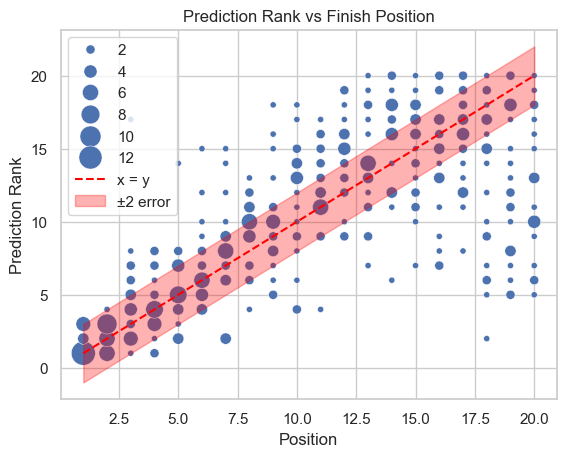

58.37% of predictions are within ±2 of x = y


In [915]:
df = results.reset_index()

# Group by coordinate pairs and count occurrences
counts = (
    df.groupby(['Position', 'PredictionRank'], as_index=False)
      .agg(Count=('RoundNumber', 'size'),
           Season=('Season', 'first'))
)

# Scatter plot with point size representing count
sns.scatterplot(
    data=counts,
    x='Position',
    y='PredictionRank',
    size='Count',
    sizes=(20, 300),
    legend=True
)

# Add reference line y = x
x_vals = np.linspace(df['Position'].min(), df['Position'].max(), 100)
plt.plot(x_vals, x_vals, color='red', linestyle='--', label='x = y')

# Add ±2 error band
plt.fill_between(x_vals, x_vals - 2, x_vals + 2, color='red', alpha=0.3, label='±2 error')

plt.xlabel('Position')
plt.ylabel('Prediction Rank')
plt.title('Prediction Rank vs Finish Position')
plt.legend()
plt.show()

# Compute % of predictions within ±2 of y = x
inside_error = (
    (df['PredictionRank'] >= df['Position'] - 2) &
    (df['PredictionRank'] <= df['Position'] + 2)
)
percentage_inside = inside_error.mean() * 100

print(f"{percentage_inside:.2f}% of predictions are within ±2 of x = y")

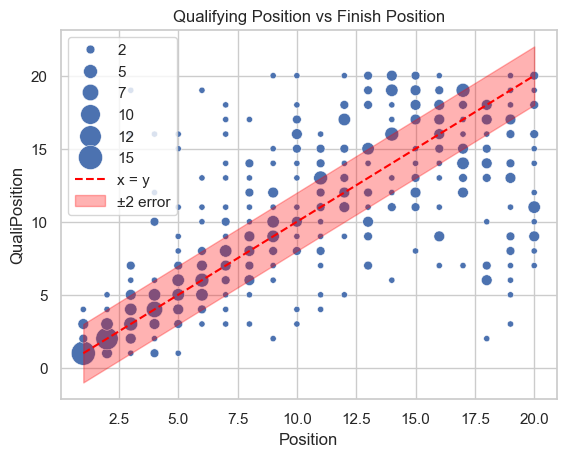

55.02% of predictions are within ±2 of x = y


In [916]:
df = results.reset_index()

# Group by coordinate pairs and count occurrences
counts = (
    df.groupby(['Position', 'QualiPosition'], as_index=False)
      .agg(Count=('RoundNumber', 'size'),
           Season=('Season', 'first'))
)

# Scatter plot with point size representing count
sns.scatterplot(
    data=counts,
    x='Position',
    y='QualiPosition',
    size='Count',
    sizes=(20, 300),
    legend=True
)

# Add reference line y = x
x_vals = np.linspace(df['Position'].min(), df['Position'].max(), 100)
plt.plot(x_vals, x_vals, color='red', linestyle='--', label='x = y')

# Add ±2 error band
plt.fill_between(x_vals, x_vals - 2, x_vals + 2, color='red', alpha=0.3, label='±2 error')

plt.xlabel('Position')
plt.ylabel('QualiPosition')
plt.title('Qualifying Position vs Finish Position')
plt.legend()
plt.show()

# Compute % of predictions within ±2 of y = x
inside_error = (
    (df['QualiPosition'] >= df['Position'] - 2) &
    (df['QualiPosition'] <= df['Position'] + 2)
)
percentage_inside = inside_error.mean() * 100

print(f"{percentage_inside:.2f}% of predictions are within ±2 of x = y")

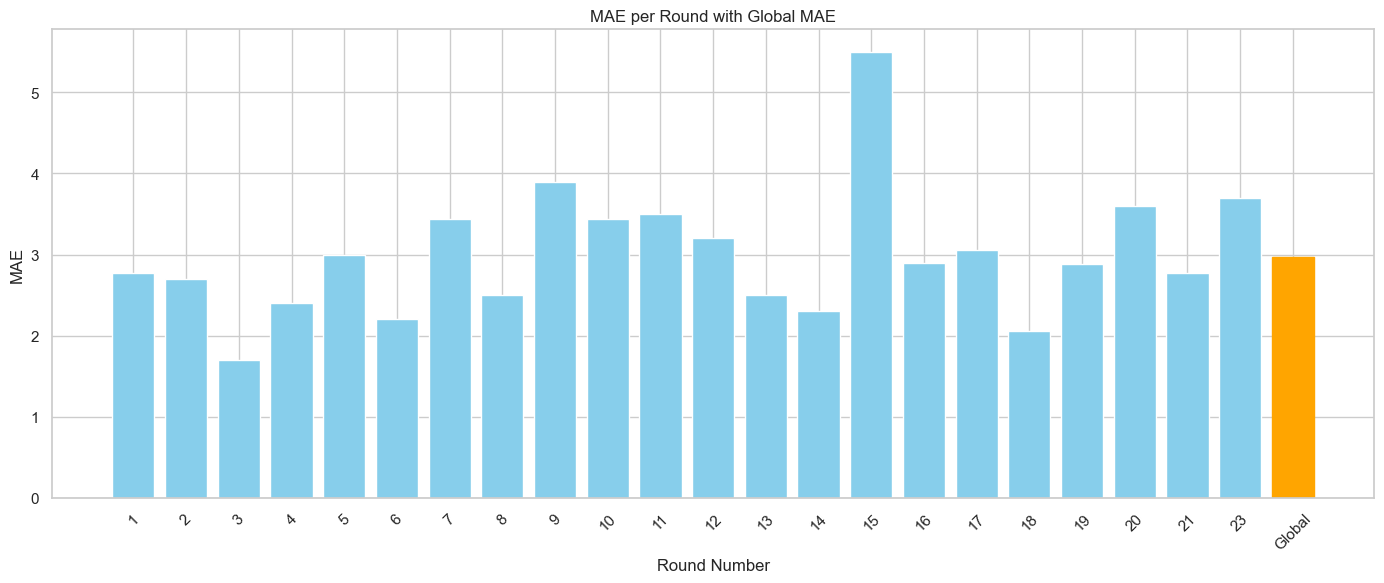

In [917]:
import matplotlib.pyplot as plt
import pandas as pd

# --- Compute MAE per event ---
rmse_per_event = results.groupby(['RoundNumber', 'Season']).apply(
    lambda df: MAE(df['Position'], df['PredictionRank'])
).reset_index(name='MAE')

# Sort by RoundNumber (1-24)
rmse_per_event = rmse_per_event.sort_values('RoundNumber')

# Compute global MAE
global_mae = MAE(results['Position'], results['PredictionRank'])

# --- Prepare data for plotting ---
# Add a row for Global MAE at the end
plot_df = pd.concat([
    rmse_per_event,
    pd.DataFrame([{'RoundNumber': 'Global', 'Season': '', 'MAE': global_mae}])
], ignore_index=True)

# --- Plot ---
plt.figure(figsize=(14, 6))
bars = plt.bar(
    x=plot_df['RoundNumber'].astype(str),  # Convert all to string for x-axis
    height=plot_df['MAE'],
    color='skyblue'
)

# Highlight Global MAE bar
bars[-1].set_color('orange')

plt.xlabel('Round Number')
plt.ylabel('MAE')
plt.title('MAE per Round with Global MAE')
plt.xticks(rotation=45)
plt.tight_layout()

          TeamName       MAE
0          McLaren  1.977273
1           Alpine  2.681818
2     Aston Martin  2.700000
3     Haas F1 Team  2.925000
4  Red Bull Racing  2.952381
5         Mercedes  3.045455
6         Williams  3.071429
7     Racing Bulls  3.075000
8          Ferrari  3.119048
9      Kick Sauber  4.325000


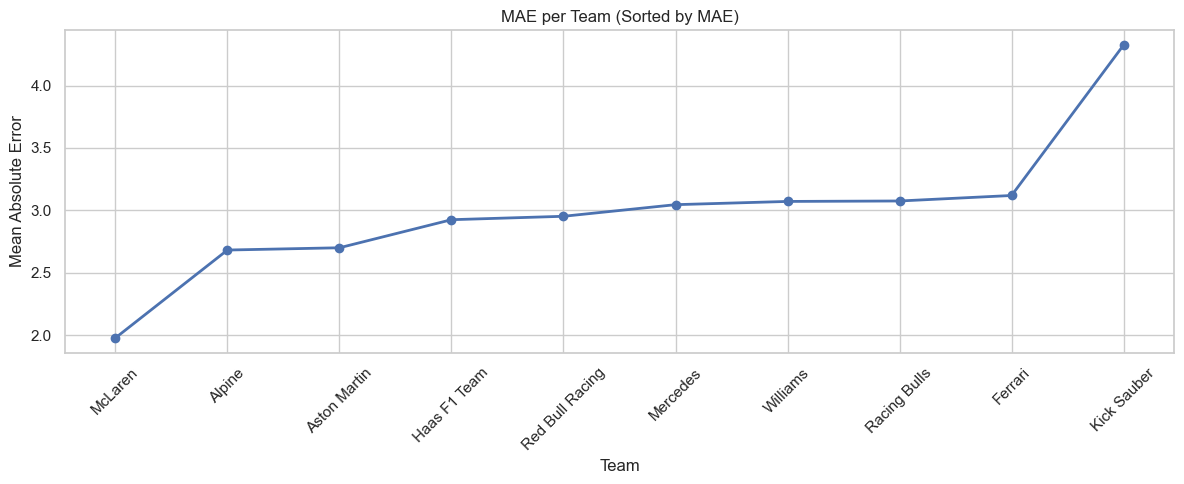

In [918]:
# Compute MAE per team
mae_values = []
team_ids = results['TeamName'].unique()

for team in team_ids:
    team_data = results[results['TeamName'] == team]
    global_mae = MAE(team_data['Position'], team_data['PredictionRank'])
    mae_values.append(global_mae)

# DataFrame for plotting
mae_df = pd.DataFrame({
    'TeamName': team_ids,
    'MAE': mae_values
})

# Sort by MAE ascending
mae_df = mae_df.sort_values("MAE", ascending=True).reset_index(drop=True)

print(mae_df)

# Plot the results
plt.figure(figsize=(12, 5))
plt.plot(mae_df['TeamName'], mae_df['MAE'], marker='o', linestyle='-', linewidth=2)
plt.title('MAE per Team (Sorted by MAE)')
plt.xlabel('Team')
plt.ylabel('Mean Absolute Error')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


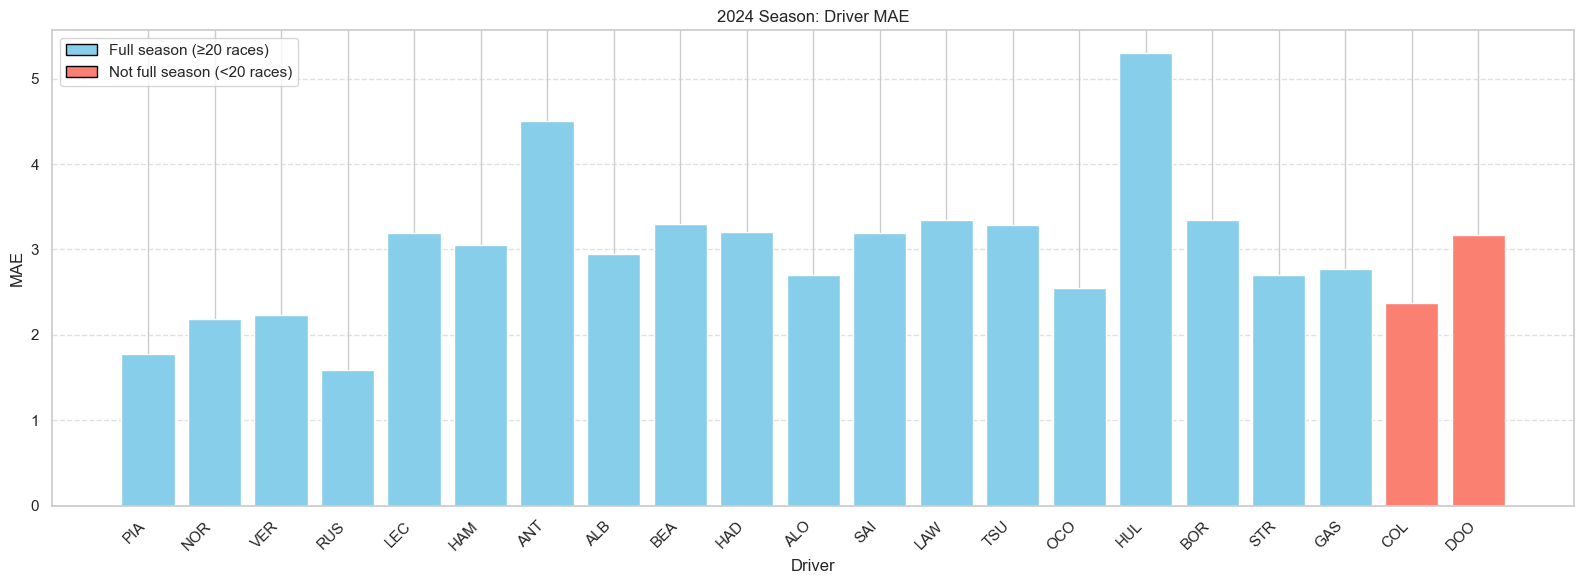

In [919]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error as MAE
import numpy as np

# Filter only 2024 season
season_data = results.reset_index()  # Assuming 'Season' is the first level of your MultiIndex

# Get unique drivers
unique_drivers = season_data['Abbreviation'].unique()  # Driver abbreviation

mae_vals = []
mean_quali = []
std_quali = []
race_counts = []

for driver in unique_drivers:
    driver_data = season_data[season_data['Abbreviation'] == driver]

    y_true = driver_data['Position'].astype(float)
    y_pred = driver_data['PredictionRank'].astype(float)

    mae_vals.append(MAE(y_true, y_pred))
    mean_quali.append(y_true.mean())
    std_quali.append(y_true.std())
    race_counts.append(len(driver_data))  # Count of races for this driver

# Build dataframe
df = pd.DataFrame({
    'Abbreviation': unique_drivers,
    'MAE': mae_vals,
    'MeanQuali': mean_quali,
    'StdQuali': std_quali,
    'RaceCount': race_counts
}).sort_values('MeanQuali').reset_index(drop=True)

# Plot
x = np.arange(len(df))
width = 0.8

# Determine bar colors
colors = ['skyblue' if races >= 20 else 'salmon' for races in df['RaceCount']]

plt.figure(figsize=(16, 6))
bars = plt.bar(x, df['MAE'], width, color=colors)

# Create custom legend for full vs not full season
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='skyblue', edgecolor='black', label='Full season (≥20 races)'),
    Patch(facecolor='salmon', edgecolor='black', label='Not full season (<20 races)')
]
plt.legend(handles=legend_elements, loc='upper left')

plt.xticks(x, df['Abbreviation'], rotation=45, ha='right')
plt.xlabel('Driver')
plt.ylabel('MAE')
plt.title('2024 Season: Driver MAE')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('DriverMAE.png', dpi=300)
plt.show()


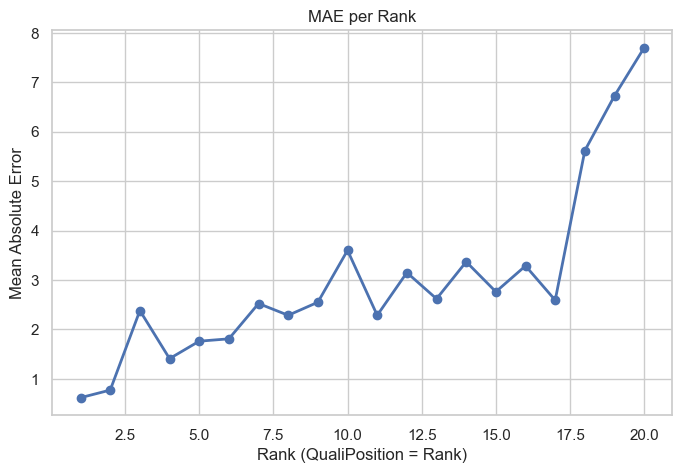

    Rank Cutoff       MAE
0             1  0.619048
1             2  0.772727
2             3  2.380952
3             4  1.409091
4             5  1.761905
5             6  1.809524
6             7  2.523810
7             8  2.285714
8             9  2.550000
9            10  3.600000
10           11  2.285714
11           12  3.150000
12           13  2.619048
13           14  3.368421
14           15  2.761905
15           16  3.285714
16           17  2.590909
17           18  5.619048
18           19  6.727273
19           20  7.700000


In [920]:
mae_values = []

for rank in range(1, 21):
    results_top_rank = results[results['Position'] == rank]
    
    # Compute global RMSE for this rank
    global_mae = MAE(results_top_rank['Position'], results_top_rank['PredictionRank'])
    mae_values.append(global_mae)

# Create a DataFrame for plotting
mae_df = pd.DataFrame({
    'Rank Cutoff': range(1, 21),
    'MAE': mae_values
})

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(mae_df['Rank Cutoff'], mae_df['MAE'], marker='o', linestyle='-', linewidth=2)
plt.title('MAE per Rank')
plt.xlabel('Rank (QualiPosition = Rank)')
plt.ylabel('Mean Absolute Error')
plt.grid(True)
plt.show()
print(mae_df)
# pred = results_top_rank[['QualiPosition', 'PredictionRank']]
# rmse = MSE(results_top_rank['QualiPosition'], results_top_rank['PredictionRank'])
# print(rmse)
# pred.head()

In [921]:
points_map = {
    1:25, 2:18, 3:15, 4:12, 5:10,
    6:8, 7:6, 8:4, 9:2, 10:1
}

In [922]:
results['actual_points'] = results['Position'].map(points_map).fillna(0)

# Calculate total championship points per driver per season
driver_champ_points = (
    results.groupby(['Season', 'Abbreviation'])['actual_points']
    .sum()
    .rename('driver_championship_points')
)


In [923]:
results['prediction_points'] = results['PredictionRank'].map(points_map).fillna(0)

# Calculate total championship points per driver per season
pred_driver_champ_points = (
    results.groupby(['Season', 'Abbreviation'])['prediction_points']
    .sum()
    .rename('predicted_driver_championship_points')
)


In [924]:
driver_champ_points = driver_champ_points.to_frame().join(pred_driver_champ_points).sort_values('driver_championship_points', ascending=False)
driver_champ_points

driver_championship_points  \
Season Abbreviation                               
2025   NOR                                379.0   
       PIA                                363.0   
       VER                                314.0   
       RUS                                261.0   
       LEC                                191.0   
       ANT                                120.0   
       HAM                                119.0   
       ALB                                 70.0   
       SAI                                 43.0   
       HUL                                 41.0   
       LAW                                 38.0   
       BEA                                 38.0   
       ALO                                 37.0   
       HAD                                 27.0   
       OCO                                 26.0   
       STR                                 22.0   
       GAS                                 20.0   
       TSU                                 20.0   
       BOR                                 19.0   
       DOO                                  0.0   
       COL                                  0.0   

                     predicted_driver_championship_points  
Season Abbreviation                                        
2025   NOR                                          421.0  
       PIA                                          463.0  
       VER                                          273.0  
       RUS                                          294.0  
       LEC                                          213.0  
       ANT                                          180.0  
       HAM                                          132.0  
       ALB                                           79.0  
       SAI                                           23.0  
       HUL                                            7.0  
       LAW                                            8.0  
       BEA                                           15.0  
       ALO                                           31.0  
       HAD                                           36.0  
       OCO                                           19.0  
       STR                                           15.0  
       GAS                                           11.0  
       TSU                                            1.0  
       BOR                                            1.0  
       DOO                                            0.0  
       COL                                            0.0

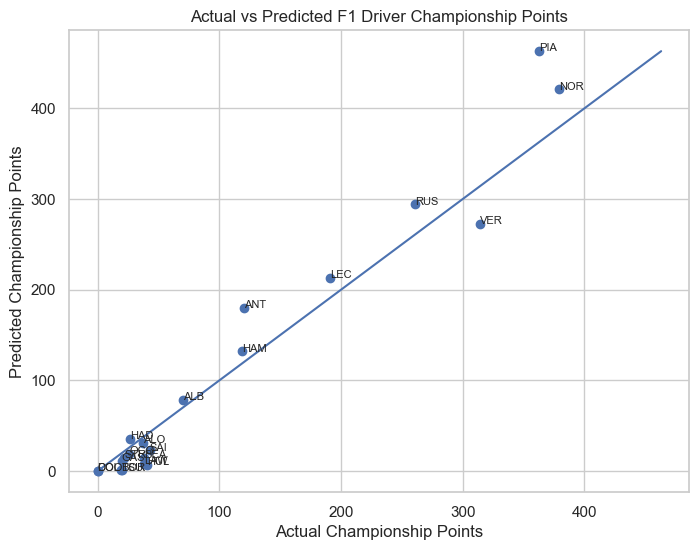

In [925]:
import matplotlib.pyplot as plt

df = driver_champ_points.reset_index()

plt.figure(figsize=(8,6))

plt.scatter(
    df['driver_championship_points'],
    df['predicted_driver_championship_points']
)

# Label drivers
for i, row in df.iterrows():
    plt.text(
        row['driver_championship_points'],
        row['predicted_driver_championship_points'],
        row['Abbreviation'],
        fontsize=8
    )

# Perfect prediction line
max_points = max(df['driver_championship_points'].max(),
                 df['predicted_driver_championship_points'].max())

plt.plot([0, max_points], [0, max_points])

plt.xlabel("Actual Championship Points")
plt.ylabel("Predicted Championship Points")
plt.title("Actual vs Predicted F1 Driver Championship Points")

plt.show()

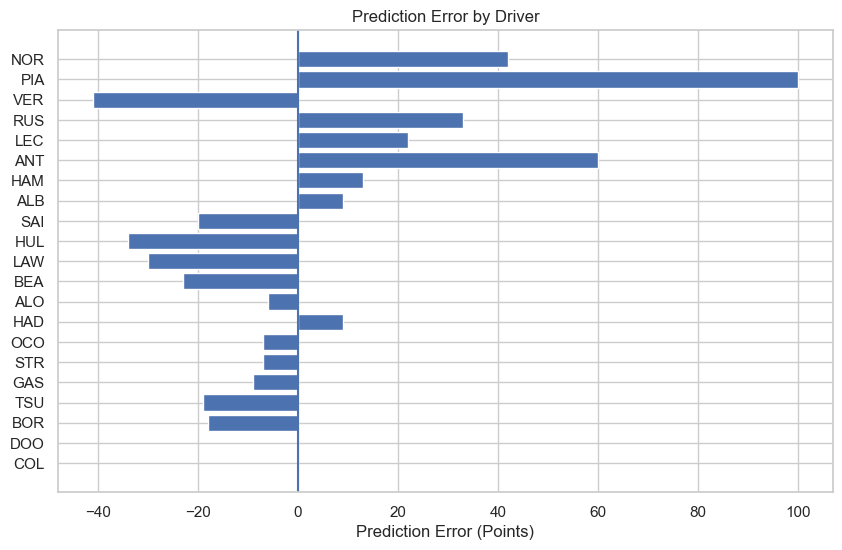

In [926]:
df['error'] = df['predicted_driver_championship_points'] - df['driver_championship_points']

df = df.sort_values('driver_championship_points')

plt.figure(figsize=(10,6))
plt.barh(df['Abbreviation'], df['error'])

plt.xlabel("Prediction Error (Points)")
plt.title("Prediction Error by Driver")

plt.axvline(0)

plt.show()

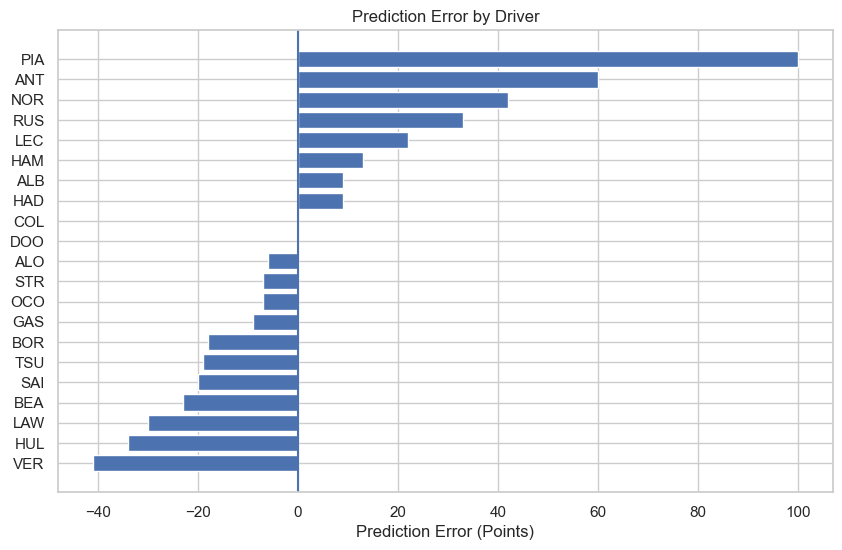

In [927]:
df['error'] = df['predicted_driver_championship_points'] - df['driver_championship_points']

df = df.sort_values('error')

plt.figure(figsize=(10,6))
plt.barh(df['Abbreviation'], df['error'])

plt.xlabel("Prediction Error (Points)")
plt.title("Prediction Error by Driver")

plt.axvline(0)

plt.show()

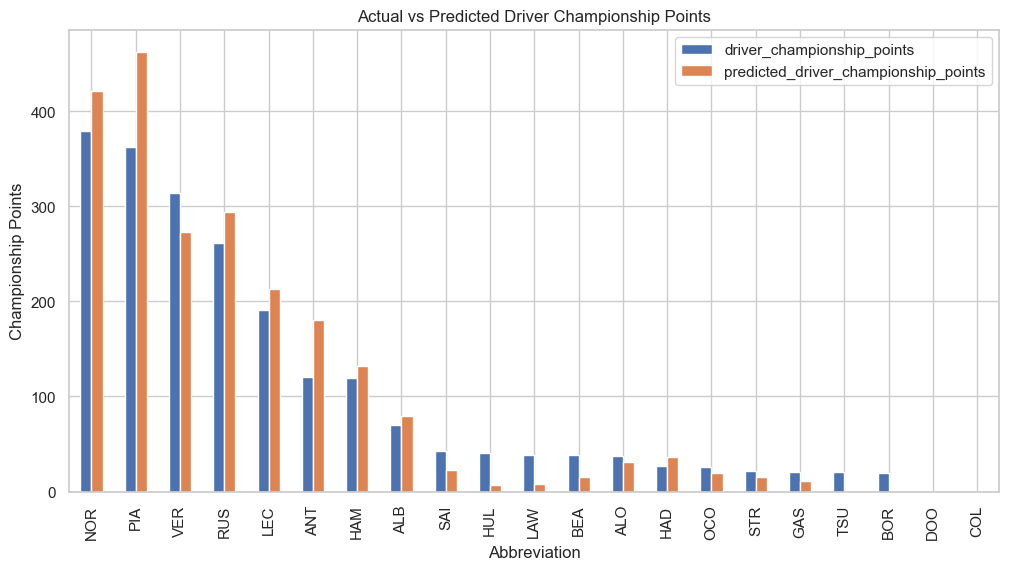

In [928]:
df = driver_champ_points.reset_index()

df = df.sort_values('driver_championship_points', ascending=False)

df.set_index('Abbreviation')[[
    'driver_championship_points',
    'predicted_driver_championship_points'
]].plot(kind='bar', figsize=(12,6))

plt.ylabel("Championship Points")
plt.title("Actual vs Predicted Driver Championship Points")
plt.show()

In [929]:
mae = (driver_champ_points['driver_championship_points'] -
       driver_champ_points['predicted_driver_championship_points']).abs().mean()

print(mae)

23.904761904761905


In [930]:
corr = driver_champ_points['driver_championship_points'].corr(
    driver_champ_points['predicted_driver_championship_points'],
    method='spearman'
)

print(corr)

0.9102147039687704


# Evaluation with no DNFs

In [931]:
results_no_dnf = results[results['ClassifiedPosition'] != 'R']
results_no_dnf

level_0  index         TeamName TeamColor  \
RoundNumber Abbreviation Season                                              
1           NOR          2025       1907   1946          McLaren    FF8000   
            VER          2025       1908   1947  Red Bull Racing    3671C6   
            RUS          2025       1909   1948         Mercedes    27F4D2   
            ANT          2025       1910   1949         Mercedes    27F4D2   
            ALB          2025       1911   1950         Williams    64C4FF   
...                                  ...    ...              ...       ...   
23          COL          2025       2328   2387           Alpine    00A1E8   
            OCO          2025       2329   2388     Haas F1 Team    9C9FA2   
            GAS          2025       2330   2389           Alpine    00A1E8   
            STR          2025       2331   2390     Aston Martin    229971   
            HAD          2025       2332   2391     Racing Bulls    6C98FF   

                                       TeamId               FullName  \
RoundNumber Abbreviation Season                                        
1           NOR          2025         mclaren           Lando Norris   
            VER          2025        red_bull         Max Verstappen   
            RUS          2025        mercedes         George Russell   
            ANT          2025        mercedes  Andrea Kimi Antonelli   
            ALB          2025        williams        Alexander Albon   
...                                       ...                    ...   
23          COL          2025          alpine       Franco Colapinto   
            OCO          2025            haas           Esteban Ocon   
            GAS          2025          alpine           Pierre Gasly   
            STR          2025    aston_martin           Lance Stroll   
            HAD          2025              rb           Isack Hadjar   

                                CountryCode  Position ClassifiedPosition  \
RoundNumber Abbreviation Season                                            
1           NOR          2025                     1.0                  1   
            VER          2025                     2.0                  2   
            RUS          2025                     3.0                  3   
            ANT          2025                     4.0                  4   
            ALB          2025                     5.0                  5   
...                                     ...       ...                ...   
23          COL          2025                    14.0                 14   
            OCO          2025                    15.0                 15   
            GAS          2025                    16.0                 16   
            STR          2025                    17.0                 17   
            HAD          2025                    18.0                 18   

                                 GridPosition                   Time  \
RoundNumber Abbreviation Season                                        
1           NOR          2025             1.0 0 days 01:42:06.304000   
            VER          2025             3.0 0 days 00:00:00.895000   
            RUS          2025             4.0 0 days 00:00:08.481000   
            ANT          2025            16.0 0 days 00:00:10.135000   
            ALB          2025             6.0 0 days 00:00:12.773000   
...                                       ...                    ...   
23          COL          2025            20.0 0 days 00:00:03.283000   
            OCO          2025            16.0 0 days 00:00:04.253000   
            GAS          2025             9.0 0 days 00:00:04.941000   
            STR          2025            18.0                    NaT   
            HAD          2025             6.0                    NaT   

                                   Status  Points  Laps    Country  \
RoundNumber Abbreviation Season                                      
1           NOR

In [932]:
mae = MAE(results_no_dnf['Position'], results_no_dnf['PredictionRank'])
print(mae)
pred = results_no_dnf[['Position', 'PredictionRank']]
pred

2.476063829787234


Position  PredictionRank
RoundNumber Abbreviation Season                          
1           NOR          2025         1.0             1.0
            VER          2025         2.0             3.0
            RUS          2025         3.0             2.0
            ANT          2025         4.0             7.0
            ALB          2025         5.0             4.0
...                                   ...             ...
23          COL          2025        14.0            20.0
            OCO          2025        15.0            16.0
            GAS          2025        16.0            11.0
            STR          2025        17.0            17.0
            HAD          2025        18.0             9.0

[376 rows x 2 columns]

In [933]:
mae = MAE(results_no_dnf['Position'], results_no_dnf['QualiPosition'])
print(mae)
pred = results_no_dnf[['Position', 'QualiPosition']]
pred

2.8085106382978724


Position  QualiPosition
RoundNumber Abbreviation Season                         
1           NOR          2025         1.0            1.0
            VER          2025         2.0            3.0
            RUS          2025         3.0            4.0
            ANT          2025         4.0           16.0
            ALB          2025         5.0            6.0
...                                   ...            ...
23          COL          2025        14.0           20.0
            OCO          2025        15.0           17.0
            GAS          2025        16.0            9.0
            STR          2025        17.0           19.0
            HAD          2025        18.0            6.0

[376 rows x 2 columns]

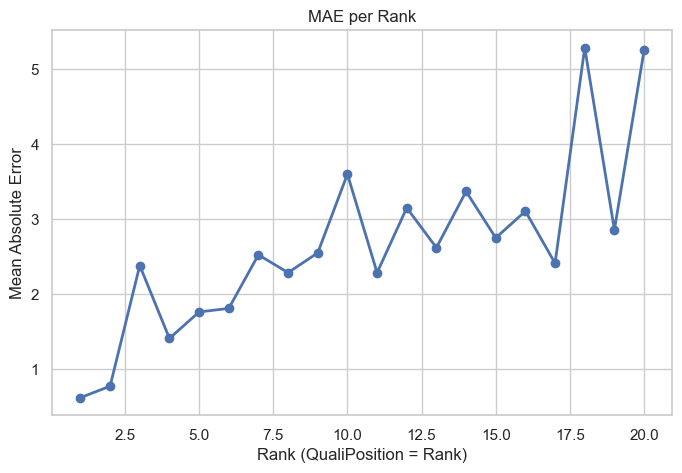

    Rank Cutoff       MAE
0             1  0.619048
1             2  0.772727
2             3  2.380952
3             4  1.409091
4             5  1.761905
5             6  1.809524
6             7  2.523810
7             8  2.285714
8             9  2.550000
9            10  3.600000
10           11  2.285714
11           12  3.150000
12           13  2.619048
13           14  3.368421
14           15  2.750000
15           16  3.105263
16           17  2.411765
17           18  5.285714
18           19  2.857143
19           20  5.250000


In [934]:
mae_values = []

for rank in range(1, 21):
    results_top_rank = results_no_dnf[results_no_dnf['Position'] == rank]
    
    # Compute global RMSE for this rank
    global_mae = MAE(results_top_rank['Position'], results_top_rank['PredictionRank'])
    mae_values.append(global_mae)

# Create a DataFrame for plotting
mae_df = pd.DataFrame({
    'Rank Cutoff': range(1, 21),
    'MAE': mae_values
})

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(mae_df['Rank Cutoff'], mae_df['MAE'], marker='o', linestyle='-', linewidth=2)
plt.title('MAE per Rank')
plt.xlabel('Rank (QualiPosition = Rank)')
plt.ylabel('Mean Absolute Error')
plt.grid(True)
plt.show()
print(mae_df)